# Early Warning for At-Risk Students

## Traditional Machine Learning vs Deep Learning on the Open University Learning Analytics Dataset (OULAD)

Joshua Rusoke Agonzibwa &nbsp;|&nbsp;

### Problem statement

Distance-learning universities lose a large share of each cohort to withdrawal and failure. Tutors can only intervene if they know *early* which students are drifting. This notebook asks:

> **Using only what the university knows 60 days after a module starts, can we predict which enrolled students will go on to fail or withdraw?**

The task is framed as binary classification (`at_risk` = Fail or Withdrawn, versus Pass or Distinction). Two modelling paradigms are built and compared on identical data splits: traditional machine learning with scikit-learn, and deep learning with TensorFlow/Keras fed by `tf.data` pipelines.

### Notebook map

| # | Section | Purpose |
|---|---------|---------|
| 1 | Setup and configuration | Imports, seeds, paths, run settings |
| 2 | Data acquisition | Download the raw dataset from UCI and load the seven tables |
| 3 | Exploratory data analysis | Understand outcomes, missingness and engagement |
| 4 | Problem framing and feature engineering | Define the day-60 cohort and build leakage-free features |
| 5 | Train / validation / test split | Split by student so nobody appears on both sides |
| 6 | Preprocessing | Imputation, log transforms, scaling, encoding |
| 7 | Traditional ML experiments | Baselines, tuning, learning curve, feature ablation, cutoff sensitivity |
| 8 | Deep learning experiments | `tf.data`, Sequential MLPs, random search, Functional embedding model |
| 9 | Final evaluation on the test set | Metrics, confusion matrices, ROC and PR curves, bootstrap intervals |
| 10 | Error analysis | Where and for whom the models fail |
| 11 | Saving artefacts | Export the best model from each paradigm |
| 12 | Conclusions and limitations | Summary to carry into the report |

**Runtime.** The notebook runs on a free Colab CPU runtime. The hyperparameter searches dominate the run time, so expect tens of minutes for a full run. Set `FAST_MODE = True` in the configuration cell for a quick end-to-end check with much smaller searches.

## 1. Setup and configuration

All imports live in one cell so the dependency list is easy to audit against `requirements.txt`. The versions are printed because results from tree ensembles and neural networks can shift slightly between library releases.

In [ ]:
import json
import shutil
import sys
import time
import urllib.request
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import tensorflow as tf
from IPython.display import display
from scipy.stats import loguniform, randint
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GroupShuffleSplit,
    RandomizedSearchCV,
    StratifiedGroupKFold,
    learning_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler,
)
from sklearn.svm import LinearSVC
from tensorflow import keras
from tensorflow.keras import layers, regularizers

LIBRARY_VERSIONS = {
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "tensorflow": tf.__version__,
    "keras": keras.__version__,
}
for name, version in LIBRARY_VERSIONS.items():
    print(f"{name:>13}: {version}")

       python: 3.13.16
        numpy: 2.1.3
       pandas: 2.2.3
        scipy: 1.16.3
 scikit-learn: 1.6.1
   tensorflow: 2.21.0
        keras: 3.13.2


The configuration cell below holds every setting that changes the experiment. `CUTOFF_DAY` is the prediction point and is the single most important design decision in the project: every feature is computed from events on or before this day, and Section 7.6 tests how the results change when it moves.

In Colab, this cell mounts Google Drive (approve the permission prompt when it appears) and saves models and figures straight to `My Drive/oulad_summative`, so they survive if the runtime disconnects or resets after the run.

In [ ]:
SEED = 42
CUTOFF_DAY = 60        # prediction point, in days after the module start date
TEST_SIZE = 0.15
VAL_SIZE = 0.15
FAST_MODE = False      # True shrinks every search for a quick end-to-end check

N_ITER = {"lr": 4, "rf": 3, "hgb": 5, "svm": 3} if FAST_MODE else {"lr": 12, "rf": 10, "hgb": 20, "svm": 8}
N_DL_TRIALS = 3 if FAST_MODE else 10
MAX_EPOCHS = 15 if FAST_MODE else 80
N_BOOTSTRAP = 200 if FAST_MODE else 1000

DATA_URL = "https://archive.ics.uci.edu/static/public/349/open+university+learning+analytics+dataset.zip"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")   # outputs go straight to Drive, so a runtime reset cannot lose them

BASE_DIR = Path("/content/oulad_project") if IN_COLAB else Path.cwd()
DATA_DIR = BASE_DIR / "data"        # raw data stays on the fast local disk
OUTPUT_DIR = Path("/content/drive/MyDrive/oulad_summative") if IN_COLAB else BASE_DIR
MODEL_DIR = OUTPUT_DIR / "models"
FIG_DIR = OUTPUT_DIR / "figures"
for directory in (DATA_DIR, MODEL_DIR, FIG_DIR):
    directory.mkdir(parents=True, exist_ok=True)

keras.utils.set_random_seed(SEED)   # seeds Python, NumPy and TensorFlow together

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def save_figure(name):
    """Save the current figure for the report, then show it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

Mounted at /content/drive


## 2. Data acquisition

**Source.** The Open University Learning Analytics Dataset (OULAD) was released by the Knowledge Media Institute at The Open University (UK) and is hosted on the UCI Machine Learning Repository under a CC BY 4.0 licence (DOI [10.24432/C5KK69](https://doi.org/10.24432/C5KK69)). It describes real, anonymised students across seven modules and four presentations in 2013 and 2014.

The raw files are downloaded at run time rather than stored in the repository, which keeps the dataset out of Git as the brief requires. The same zip file is the one to upload to the Google Drive folder.

In [ ]:
REQUIRED_FILES = [
    "assessments.csv",
    "courses.csv",
    "studentAssessment.csv",
    "studentInfo.csv",
    "studentRegistration.csv",
    "studentVle.csv",
    "vle.csv",
]


def fetch_oulad(url=DATA_URL, data_dir=DATA_DIR):
    """Download and extract OULAD once, and return the path of each CSV table."""

    def find_tables():
        return {path.name: path for path in data_dir.rglob("*.csv")}

    zip_path = data_dir / "oulad_raw.zip"
    found = find_tables()
    if not all(name in found for name in REQUIRED_FILES):
        if not zip_path.exists():
            print(f"Downloading {url}")
            request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(request) as response, open(zip_path, "wb") as out:
                shutil.copyfileobj(response, out)
        with zipfile.ZipFile(zip_path) as archive:
            archive.extractall(data_dir)
        # Some mirrors wrap the tables in a second archive.
        for nested in list(data_dir.rglob("*.zip")):
            if nested != zip_path:
                with zipfile.ZipFile(nested) as archive:
                    archive.extractall(nested.parent)
        found = find_tables()

    missing = [name for name in REQUIRED_FILES if name not in found]
    if missing:
        raise FileNotFoundError(f"Missing tables after extraction: {missing}")
    return {name: found[name] for name in REQUIRED_FILES}


table_paths = fetch_oulad()
for name, path in table_paths.items():
    print(f"{name:<24} {path.stat().st_size / 1e6:8.1f} MB")

assessments.csv               0.0 MB
courses.csv                   0.0 MB
studentAssessment.csv         5.7 MB
studentInfo.csv               3.5 MB
studentRegistration.csv       1.1 MB
studentVle.csv              453.8 MB
vle.csv                       0.3 MB


### 2.1 Loading the tables

OULAD is relational. Each row of `studentInfo` is one *enrolment*: a student taking one module in one presentation. Because the same student can appear in several enrolments, a surrogate key `enrol_id` is created and attached to the 10.6 million clickstream rows. This replaces a three-column string key with one integer, which keeps the later group-by operations fast and memory-light.

Dates in every table are counted in days relative to the module start (day 0), so negative values are events before the module began.

In [ ]:
KEYS = ["code_module", "code_presentation"]
ENROL_KEYS = KEYS + ["id_student"]
NA_VALUES = ["?", ""]


def load_tables(paths):
    """Read the seven OULAD tables and return them with the raw shapes."""

    def read(name, **kwargs):
        return pd.read_csv(paths[name], na_values=NA_VALUES, **kwargs)

    info = read("studentInfo.csv")
    registration = read("studentRegistration.csv")
    courses = read("courses.csv")
    assessments = read("assessments.csv")
    student_assessment = read("studentAssessment.csv")
    vle = read("vle.csv")
    student_vle = read(
        "studentVle.csv",
        dtype={
            "code_module": "category",
            "code_presentation": "category",
            "id_student": "int32",
            "id_site": "int32",
            "date": "int16",
            "sum_click": "int32",
        },
    )

    raw_shapes = pd.DataFrame(
        {
            "rows": [len(t) for t in (info, registration, courses, assessments, student_assessment, vle, student_vle)],
            "columns": [t.shape[1] for t in (info, registration, courses, assessments, student_assessment, vle, student_vle)],
        },
        index=["studentInfo", "studentRegistration", "courses", "assessments", "studentAssessment", "vle", "studentVle"],
    )

    info = info.drop_duplicates(ENROL_KEYS).reset_index(drop=True)
    info["imd_band"] = info["imd_band"].str.replace("%", "", regex=False)   # one band is stored without its % sign
    info["enrol_id"] = np.arange(len(info), dtype="int32")
    registration = registration.drop_duplicates(ENROL_KEYS)

    # Swap the three-column enrolment key on the clickstream for the integer enrol_id.
    student_vle = student_vle.merge(info[ENROL_KEYS + ["enrol_id"]], on=ENROL_KEYS, how="inner")
    student_vle = student_vle.drop(columns=ENROL_KEYS)
    site_type = vle.drop_duplicates("id_site").set_index("id_site")["activity_type"]
    student_vle["activity_type"] = student_vle["id_site"].map(site_type).astype("category")

    tables = {
        "info": info,
        "registration": registration,
        "courses": courses,
        "assessments": assessments,
        "student_assessment": student_assessment,
        "vle": vle,
        "student_vle": student_vle,
    }
    return tables, raw_shapes


tables, raw_shapes = load_tables(table_paths)
info = tables["info"]
student_vle = tables["student_vle"]

display(raw_shapes)
assert raw_shapes.loc["studentInfo", "rows"] >= 20_000, "The brief requires at least 20,000 raw rows."
print(f"Enrolments (rows in studentInfo): {len(info):,}")
print(f"Distinct students:               {info['id_student'].nunique():,}")

,rows,columns
studentInfo,32593,12
studentRegistration,32593,5
courses,22,3
assessments,206,6
studentAssessment,173912,5
vle,6364,6
studentVle,10655280,6


Enrolments (rows in studentInfo): 32,593
Distinct students:               28,785


**Interpretation.** `studentInfo` has 32,593 rows, which is well above the 20,000-row minimum in the brief. The rows cover 28,785 distinct students, so 3,808 enrolments (11.7%) belong to a student who appears more than once, either retaking a module or taking two modules at the same time. If those students were split at random by row, their stable traits would appear on both sides of the train/test boundary. This is why Section 5 splits by student rather than by row.

## 3. Exploratory data analysis

The aim of this section is to learn enough about the data to make defensible modelling decisions, not to produce charts for their own sake. Each plot answers a question that changes something later in the pipeline.

### 3.1 Structure and missing values

In [ ]:
display(info.head())

missing = pd.DataFrame({
    "table": ["studentInfo"] * info.shape[1],
    "column": info.columns,
    "missing": info.isna().sum().to_numpy(),
    "missing_pct": (info.isna().mean() * 100).round(2).to_numpy(),
})
for table_name in ("registration", "assessments", "student_assessment"):
    frame = tables[table_name]
    missing = pd.concat([missing, pd.DataFrame({
        "table": table_name,
        "column": frame.columns,
        "missing": frame.isna().sum().to_numpy(),
        "missing_pct": (frame.isna().mean() * 100).round(2).to_numpy(),
    })])
display(missing[missing["missing"] > 0].reset_index(drop=True))

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,enrol_id
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100,55<=,0,240,N,Pass,0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30,35-55,0,60,N,Pass,1
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40,35-55,0,60,Y,Withdrawn,2
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60,35-55,0,60,N,Pass,3
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60,0-35,0,60,N,Pass,4


,table,column,missing,missing_pct
0,studentInfo,imd_band,1111,3.41
1,registration,date_registration,45,0.14
2,registration,date_unregistration,22521,69.10
3,assessments,date,11,5.34
4,student_assessment,score,173,0.10


**Interpretation.** Each of the three kinds of missingness needs a different treatment.

* `imd_band` is missing for 1,111 enrolments (3.4%). Not disclosing a postcode may itself carry information, so missing values become an explicit "Unknown" category rather than being imputed.
* `date_unregistration` is missing for 22,521 enrolments (69.1%). These are simply the students who never withdrew, so the gap is structural rather than an error. The field also leaks the target directly: a student with an unregistration date is, by definition, Withdrawn. It is therefore used only to define the cohort and is never a feature.
* Only 11 assessment dates are missing (all exams, which are excluded from the features) and 173 scores (0.1%). The aggregation and median imputation in the pipeline absorb these.

### 3.2 What does the target look like?

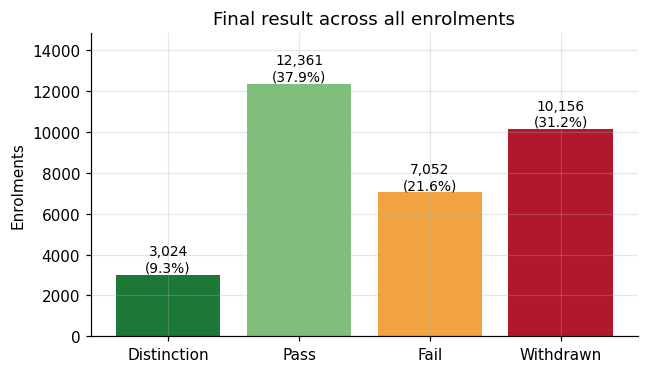

In [ ]:
OUTCOME_ORDER = ["Distinction", "Pass", "Fail", "Withdrawn"]
OUTCOME_COLORS = {"Distinction": "#1b7837", "Pass": "#7fbf7b", "Fail": "#f1a340", "Withdrawn": "#b2182b"}

outcome_counts = info["final_result"].value_counts().reindex(OUTCOME_ORDER)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(outcome_counts.index, outcome_counts.to_numpy(), color=[OUTCOME_COLORS[o] for o in OUTCOME_ORDER])
for x, count in enumerate(outcome_counts.to_numpy()):
    ax.text(x, count, f"{count:,}\n({count / len(info):.1%})", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Enrolments")
ax.set_title("Final result across all enrolments")
ax.margins(y=0.2)
save_figure("eda_outcome_distribution")

**Interpretation.** Pass is the largest outcome (37.9%), followed by Withdrawn (31.2%), Fail (21.6%) and Distinction (9.3%). As a four-class problem the data are imbalanced: Distinction is about a quarter the size of Pass. Merging the classes into on track (Pass, Distinction) and at risk (Fail, Withdrawn) gives a 47/53 split across all enrolments. The merge matches the decision a tutor actually faces, because the action (contact the student and offer support) is the same whether the student is heading for a fail or a withdrawal. Section 4 shows that the split becomes 58/42 once students who left before day 60 are removed.

### 3.3 Do outcomes differ by module and by student background?

If outcome rates vary strongly between modules, the module must be a feature and results should be broken down by module in the error analysis. If they vary by deprivation band or prior education, the model will pick up socio-economic signal, which raises a fairness question examined in Section 10.

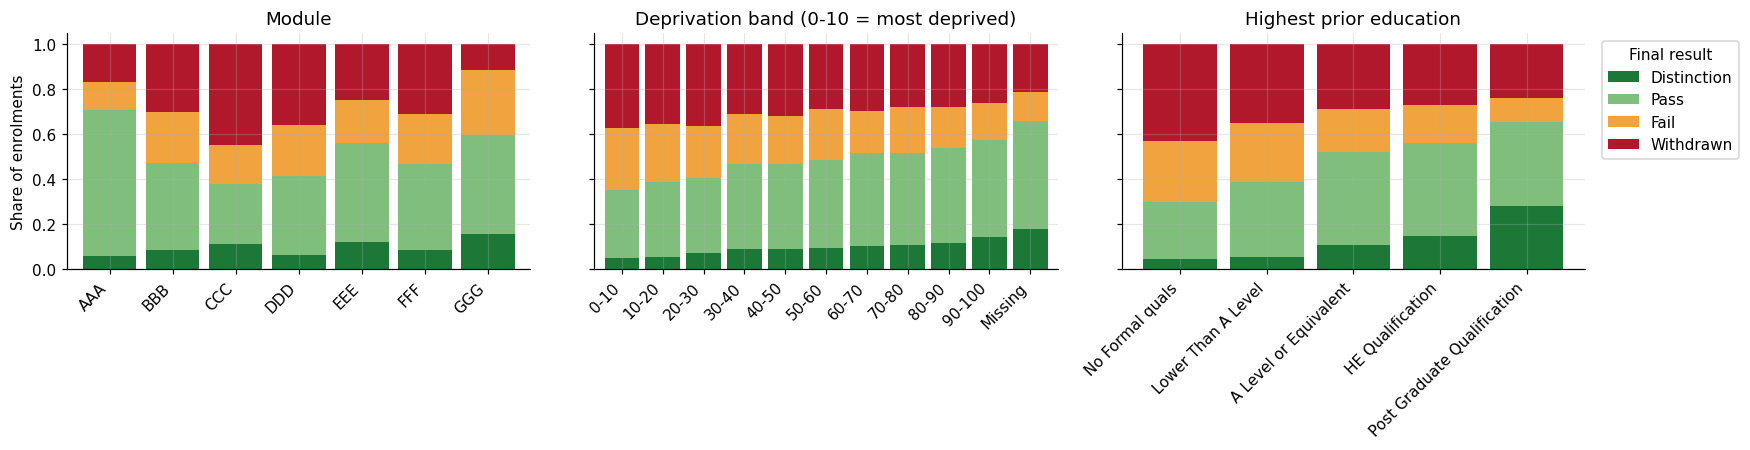

In [ ]:
def outcome_share(column, order=None):
    """Row-normalised share of each final result within the levels of one column."""
    share = pd.crosstab(info[column].fillna("Missing"), info["final_result"], normalize="index")[OUTCOME_ORDER]
    return share.reindex(order) if order else share


IMD_ORDER = [f"{low}-{low + 10}" for low in range(0, 100, 10)] + ["Missing"]
EDUCATION_ORDER = [
    "No Formal quals",
    "Lower Than A Level",
    "A Level or Equivalent",
    "HE Qualification",
    "Post Graduate Qualification",
]

panels = [
    ("code_module", None, "Module"),
    ("imd_band", IMD_ORDER, "Deprivation band (0-10 = most deprived)"),
    ("highest_education", EDUCATION_ORDER, "Highest prior education"),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, (column, order, title) in zip(axes, panels):
    outcome_share(column, order).plot(
        kind="bar", stacked=True, ax=ax, width=0.85, legend=False,
        color=[OUTCOME_COLORS[o] for o in OUTCOME_ORDER],
    )
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
    plt.setp(ax.get_xticklabels(), ha="right")
axes[0].set_ylabel("Share of enrolments")
axes[-1].legend(OUTCOME_ORDER, title="Final result", bbox_to_anchor=(1.02, 1), loc="upper left")
save_figure("eda_outcome_by_group")

**Interpretation.** Outcomes differ sharply between modules. In CCC and DDD roughly 60% of enrolments end in Fail or Withdrawn, compared with about 30% in AAA. GGG has an unusual profile, with few withdrawals but a large fail share. Both background variables show a clear gradient. The at-risk share falls from about 65% in the most deprived band (0–10) to about 42% in the least deprived (90–100), and from about 70% for students with no formal qualifications to about 35% for postgraduates.

These variables therefore carry real predictive signal, and `code_module` must be a feature. The gradients also raise a fairness question. A model that uses deprivation and prior education will flag disadvantaged students more often. That is useful if the flag leads to extra support, but it risks stereotyping if the flag leads to anything restrictive. Section 10.3 measures how large this effect is.

### 3.4 When do students withdraw?

This plot decides how the cohort is defined. A student who has already withdrawn by the prediction day does not need a prediction, and including them would inflate every metric with cases that are trivially easy.

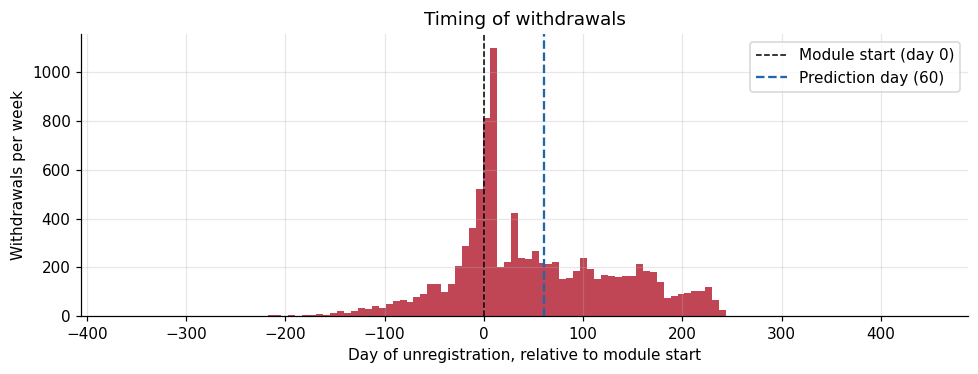

Withdrawals recorded:            10,072
  on or before day 0:            30.7%
  on or before day 60:           61.9%


In [ ]:
unregistered = tables["registration"]["date_unregistration"].dropna()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(unregistered, bins=range(int(unregistered.min()), int(unregistered.max()) + 8, 7), color="#b2182b", alpha=0.8)
ax.axvline(0, color="black", linestyle="--", linewidth=1, label="Module start (day 0)")
ax.axvline(CUTOFF_DAY, color="#2166ac", linestyle="--", linewidth=1.5, label=f"Prediction day ({CUTOFF_DAY})")
ax.set_xlabel("Day of unregistration, relative to module start")
ax.set_ylabel("Withdrawals per week")
ax.set_title("Timing of withdrawals")
ax.legend()
save_figure("eda_withdrawal_timing")

print(f"Withdrawals recorded:            {len(unregistered):,}")
print(f"  on or before day 0:            {(unregistered <= 0).mean():.1%}")
print(f"  on or before day {CUTOFF_DAY}:           {(unregistered <= CUTOFF_DAY).mean():.1%}")

**Interpretation.** Of the 10,072 recorded withdrawals, 30.7% happen on or before day 0 and 61.9% by day 60. These students are excluded from the modelling cohort, because a prediction about a student who has already left is of no use. The exclusion also has a cost: a day-60 model cannot help the majority of withdrawers, who leave before it runs. This trade-off recurs throughout the notebook. A later prediction day gives the model more behaviour to learn from, but by then more students are beyond help. Section 7.6 measures this directly.

### 3.5 Does online engagement separate the outcomes early?

The clickstream is the richest table. Before engineering features from it, this plot checks whether weekly activity differs between outcome groups *before* the prediction day. If the curves only separate late in the module, an early-warning model has little to work with.

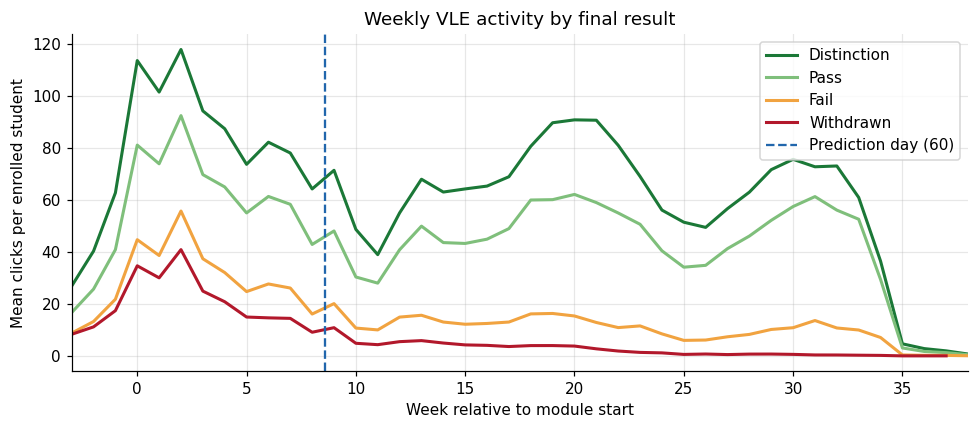

In [ ]:
weekly_clicks = (
    student_vle.groupby(["enrol_id", (student_vle["date"] // 7).rename("week")])["sum_click"].sum().reset_index()
)
weekly_clicks = weekly_clicks.merge(info[["enrol_id", "final_result"]], on="enrol_id")
clicks_per_student = (
    weekly_clicks.groupby(["final_result", "week"])["sum_click"].sum().unstack("final_result")
    / info["final_result"].value_counts()
)

fig, ax = plt.subplots(figsize=(9, 4))
for outcome in OUTCOME_ORDER:
    ax.plot(clicks_per_student.index, clicks_per_student[outcome], label=outcome, color=OUTCOME_COLORS[outcome], linewidth=2)
ax.axvline(CUTOFF_DAY / 7, color="#2166ac", linestyle="--", linewidth=1.5, label=f"Prediction day ({CUTOFF_DAY})")
ax.set_xlim(-3, 38)
ax.set_xlabel("Week relative to module start")
ax.set_ylabel("Mean clicks per enrolled student")
ax.set_title("Weekly VLE activity by final result")
ax.legend()
save_figure("eda_weekly_clicks_by_outcome")
del weekly_clicks

**Interpretation.** The four groups are already separated before the module starts, and the separation persists. In the first two weeks, Distinction students average about 100–115 clicks per week, Pass students about 80–90, Fail students about 45–55 and Withdrawn students about 35–40. The ordering never changes. Early engagement is therefore a usable signal, which supports an early-warning design.

The curves also show where the difficulty lies. Pass sits close to Distinction, and Fail sits close to Withdrawn. The hard boundary is between Pass and Fail, which are about a factor of two apart on average but overlap heavily student by student (Section 5.1). Section 10 shows that this is exactly where most errors occur. Withdrawn students fall to almost zero clicks after week 10, but that happens after the prediction day and is not available to the model.

## 4. Problem framing and feature engineering

### 4.1 Target and cohort

* **Target.** `at_risk = 1` if the final result is Fail or Withdrawn, otherwise 0.
* **Cohort.** Enrolments that are still active on `CUTOFF_DAY`: the student registered on or before that day and had not unregistered by then.
* **Leakage rule.** Every feature uses only events dated on or before `CUTOFF_DAY`. The unregistration date, the final exam and any later clicks or submissions are never seen by the model.

### 4.2 Feature families

| Family | Examples | Rationale |
|--------|----------|-----------|
| Background | module, region, prior education, deprivation band, age band, disability, previous attempts, credits studied, days registered before start, concurrent modules | Known at enrolment; a model using only these is the "day 0" baseline |
| VLE engagement | total clicks, active days, distinct resources, clicks per week, weekly trend and variability, days since last login, clicks by activity type, clicks relative to the cohort median | Behavioural signal; the trend and recency features describe *disengagement*, not just volume |
| Assessment | assessments due and submitted, submission rate, mean, minimum and weighted score, days submitted early, late submissions | Direct evidence of academic performance so far |

`vle_clicks_vs_cohort` divides a student's clicks by the median of their own module presentation, because modules differ greatly in how much online activity they require. It uses only cohort *features* available on the prediction day, not labels.

In [ ]:
TARGET = "at_risk"
AT_RISK_OUTCOMES = ["Fail", "Withdrawn"]
ACTIVITY_TYPES = ["homepage", "oucontent", "forumng", "subpage", "resource", "quiz", "url", "ouwiki"]
CATEGORICAL_COLS = [
    "code_module",
    "pres_semester",
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "disability",
]
META_COLS = ["id_student", "code_presentation", "final_result", TARGET]


def build_vle_features(student_vle, cutoff_day):
    """Aggregate each enrolment's clickstream up to and including cutoff_day."""
    window = student_vle.loc[student_vle["date"] <= cutoff_day]

    feats = window.groupby("enrol_id").agg(
        vle_total_clicks=("sum_click", "sum"),
        vle_active_days=("date", "nunique"),
        vle_distinct_sites=("id_site", "nunique"),
        vle_first_day=("date", "min"),
        vle_last_day=("date", "max"),
    )
    feats["vle_days_since_last"] = cutoff_day - feats["vle_last_day"]
    feats["vle_clicks_per_active_day"] = feats["vle_total_clicks"] / feats["vle_active_days"]
    feats = feats.drop(columns="vle_last_day")

    # Weekly click counts; everything before the start date is pooled into one "pre" week.
    weeks = list(range(-1, cutoff_day // 7 + 1))
    week = (window["date"] // 7).clip(lower=-1).rename("week")
    weekly = window.groupby(["enrol_id", week])["sum_click"].sum().unstack(fill_value=0)
    weekly = weekly.reindex(index=feats.index, columns=weeks, fill_value=0)

    in_course = weekly[[w for w in weeks if w >= 0]].to_numpy(dtype="float64")
    feats["vle_weekly_std"] = in_course.std(axis=1)
    feats["vle_weeks_active"] = (in_course > 0).mean(axis=1)
    if in_course.shape[1] >= 2:
        # Least-squares slope of clicks against week number: negative means fading engagement.
        centred_week = np.arange(in_course.shape[1]) - (in_course.shape[1] - 1) / 2
        centred_clicks = in_course - in_course.mean(axis=1, keepdims=True)
        feats["vle_weekly_slope"] = centred_clicks @ centred_week / (centred_week ** 2).sum()
    else:
        feats["vle_weekly_slope"] = 0.0
    weekly.columns = ["vle_wk_pre" if w < 0 else f"vle_wk_{w:02d}" for w in weeks]

    by_type = window.groupby(["enrol_id", "activity_type"], observed=True)["sum_click"].sum().unstack(fill_value=0)
    by_type.columns = by_type.columns.astype(str)
    by_type = by_type.reindex(index=feats.index, columns=ACTIVITY_TYPES, fill_value=0)
    by_type.columns = [f"vle_act_{name}" for name in ACTIVITY_TYPES]
    by_type["vle_act_other"] = feats["vle_total_clicks"] - by_type.sum(axis=1)

    return feats.join(weekly).join(by_type)


def build_assessment_features(tables, cutoff_day):
    """Summarise coursework that was both due and submitted by cutoff_day."""
    assessments = tables["assessments"]
    due = assessments[(assessments["assessment_type"] != "Exam") & (assessments["date"] <= cutoff_day)]
    due_summary = (
        due.groupby(KEYS)
        .agg(asm_n_due=("id_assessment", "count"), asm_weight_due=("weight", "sum"))
        .reset_index()
    )

    sub = tables["student_assessment"].merge(
        due[["id_assessment", *KEYS, "date", "weight"]], on="id_assessment", how="inner"
    )
    sub = sub[sub["date_submitted"] <= cutoff_day]
    sub = sub.merge(tables["info"][ENROL_KEYS + ["enrol_id"]], on=ENROL_KEYS, how="inner")
    sub["days_early"] = sub["date"] - sub["date_submitted"]
    sub["is_late"] = (sub["days_early"] < 0).astype(int)
    sub["weighted_points"] = sub["score"] * sub["weight"]
    sub["scored_weight"] = sub["weight"].where(sub["score"].notna())

    feats = sub.groupby("enrol_id").agg(
        asm_n_submitted=("id_assessment", "nunique"),
        asm_mean_score=("score", "mean"),
        asm_min_score=("score", "min"),
        asm_mean_days_early=("days_early", "mean"),
        asm_n_late=("is_late", "sum"),
        asm_n_banked=("is_banked", "sum"),
        points=("weighted_points", "sum"),
        weight=("scored_weight", "sum"),
    )
    feats["asm_weighted_score"] = feats["points"] / feats["weight"].where(feats["weight"] > 0)
    return feats.drop(columns=["points", "weight"]), due_summary


def build_features(tables, cutoff_day=CUTOFF_DAY):
    """Return one row per enrolment still active on cutoff_day, with features and target."""
    df = (
        tables["info"]
        .merge(tables["registration"], on=ENROL_KEYS, how="left")
        .merge(tables["courses"], on=KEYS, how="left")
    )
    still_enrolled = df["date_unregistration"].isna() | (df["date_unregistration"] > cutoff_day)
    registered = df["date_registration"].isna() | (df["date_registration"] <= cutoff_day)
    df = df.loc[still_enrolled & registered].copy()

    df[TARGET] = df["final_result"].isin(AT_RISK_OUTCOMES).astype("int8")
    df["pres_semester"] = df["code_presentation"].str[-1].map({"B": "February", "J": "October"})
    df["reg_days_before_start"] = -df["date_registration"]
    df["n_concurrent_modules"] = df.groupby(["id_student", "code_presentation"])["code_module"].transform("count")

    assessment_feats, due_summary = build_assessment_features(tables, cutoff_day)
    df = df.merge(due_summary, on=KEYS, how="left").set_index("enrol_id")
    df = df.join(build_vle_features(tables["student_vle"], cutoff_day)).join(assessment_feats)

    # A student with no clicks or no submissions has a true count of zero, not a missing value.
    zero_fill = [c for c in df.columns if c.startswith(("vle_wk_", "vle_act_"))] + [
        "vle_total_clicks", "vle_active_days", "vle_distinct_sites", "vle_clicks_per_active_day",
        "vle_weekly_std", "vle_weeks_active", "vle_weekly_slope",
        "asm_n_due", "asm_weight_due", "asm_n_submitted", "asm_n_late", "asm_n_banked",
    ]
    df[zero_fill] = df[zero_fill].fillna(0)

    df["vle_no_activity"] = (df["vle_total_clicks"] == 0).astype("int8")
    cohort_median = df.groupby(KEYS)["vle_total_clicks"].transform("median")
    df["vle_clicks_vs_cohort"] = df["vle_total_clicks"] / cohort_median.where(cohort_median > 0)
    df["asm_submission_rate"] = df["asm_n_submitted"] / df["asm_n_due"].where(df["asm_n_due"] > 0)
    df["asm_n_missing"] = (df["asm_n_due"] - df["asm_n_submitted"]).clip(lower=0)

    df[CATEGORICAL_COLS] = df[CATEGORICAL_COLS].astype(object)
    return df.drop(columns=["date_registration", "date_unregistration"])


def numeric_feature_columns(df):
    return [c for c in df.columns if c not in META_COLS + CATEGORICAL_COLS]


def feature_groups(numeric_cols):
    """Split the numeric features into the three families used in the ablation study."""
    vle = [c for c in numeric_cols if c.startswith("vle_")]
    assessment = [c for c in numeric_cols if c.startswith("asm_")]
    background = [c for c in numeric_cols if c not in vle + assessment]
    return {"background": background, "vle": vle, "assessment": assessment}


features = build_features(tables, CUTOFF_DAY)
NUMERIC_COLS = numeric_feature_columns(features)
FEATURE_COLS = NUMERIC_COLS + CATEGORICAL_COLS
GROUPS = feature_groups(NUMERIC_COLS)

cohort_summary = pd.Series({
    "Raw enrolments": len(info),
    f"Removed (left or not yet registered by day {CUTOFF_DAY})": len(info) - len(features),
    "Modelling cohort": len(features),
    "At-risk share in cohort": round(features[TARGET].mean(), 4),
    "Categorical features": len(CATEGORICAL_COLS),
    "Numeric features: background": len(GROUPS["background"]),
    "Numeric features: VLE": len(GROUPS["vle"]),
    "Numeric features: assessment": len(GROUPS["assessment"]),
}, dtype=object)
display(cohort_summary.to_frame("value"))
display(pd.crosstab(features["final_result"], features[TARGET]).reindex(OUTCOME_ORDER))
display(features[NUMERIC_COLS].describe().T.round(2))

,value
Raw enrolments,32593
Removed (left or not yet registered by day 60),6240
Modelling cohort,26353
At-risk share in cohort,0.4163
Categorical features,8
Numeric features: background,5
Numeric features: VLE,30
Numeric features: assessment,11


at_risk,0,1
final_result,,
Distinction,3024,0
Pass,12358,0
Fail,0,7040
Withdrawn,0,3931


,count,mean,std,min,25%,50%,75%,max
num_of_prev_attempts,26353.0,0.16,0.47,0.00,0.00,0.00,0.00,6.00
studied_credits,26353.0,75.74,37.70,30.00,60.00,60.00,90.00,630.00
module_presentation_length,26353.0,256.01,13.16,234.00,241.00,262.00,268.00,269.00
reg_days_before_start,26346.0,66.03,47.38,-59.00,29.00,53.00,95.00,311.00
n_concurrent_modules,26353.0,1.04,0.20,1.00,1.00,1.00,1.00,2.00
asm_n_due,26353.0,1.97,0.89,0.00,2.00,2.00,2.00,4.00
asm_weight_due,26353.0,18.26,8.06,0.00,11.00,22.50,25.00,30.00
vle_total_clicks,26353.0,582.82,690.14,0.00,154.00,366.00,759.00,11102.00
vle_active_days,26353.0,25.67,17.66,0.00,12.00,23.00,37.00,86.00
vle_distinct_sites,26353.0,38.57,27.95,0.00,18.00,32.00,54.00,299.00


**Interpretation.** The modelling cohort has 26,353 enrolments. Another 6,240 (19.1%) were removed because the student had left, or had not yet registered, by day 60. The at-risk share is 41.6%, a 58/42 split, so the problem is close to balanced. Accuracy is therefore meaningful, although ROC-AUC, PR-AUC, precision and recall remain the primary metrics. No resampling or class weighting is needed by default; class weighting is offered to the logistic regression search as an option.

The `describe` table confirms heavy right skew in the click features. `vle_total_clicks` has a median of 366 but a mean of 583 and a standard deviation of 690, and weekly click counts behave the same way. This motivates the `log1p` transform in Section 6. The engineered features end up as 5 numeric background features, 30 VLE features, 11 assessment features and 8 categorical features.

## 5. Train / validation / test split

Roughly 70 / 15 / 15. The split is made **by student**, not by row: a student who retakes a module, or takes two at once, would otherwise sit in both training and test data, and their stable traits would leak across the boundary and make the test score optimistic.

The three sets have fixed roles. The **training** set fits models and is the only data seen by cross-validated hyperparameter search. The **validation** set compares models, drives Keras early stopping and chooses decision thresholds. The **test** set is touched once, in Section 9.

In [ ]:
def split_by_student(df, test_size=TEST_SIZE, val_size=VAL_SIZE, seed=SEED):
    """Split enrolments into train, validation and test with no student shared between them."""
    groups = df["id_student"].to_numpy()
    outer = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    trainval_idx, test_idx = next(outer.split(df, groups=groups))
    inner = GroupShuffleSplit(n_splits=1, test_size=val_size / (1 - test_size), random_state=seed)
    train_idx, val_idx = next(inner.split(df.iloc[trainval_idx], groups=groups[trainval_idx]))
    return df.iloc[trainval_idx[train_idx]], df.iloc[trainval_idx[val_idx]], df.iloc[test_idx]


train_df, val_df, test_df = split_by_student(features)

for left, right in ((train_df, val_df), (train_df, test_df), (val_df, test_df)):
    assert not set(left["id_student"]) & set(right["id_student"]), "A student appears in two splits."

X_train, y_train, groups_train = train_df[FEATURE_COLS], train_df[TARGET].to_numpy(), train_df["id_student"].to_numpy()
X_val, y_val = val_df[FEATURE_COLS], val_df[TARGET].to_numpy()
X_test, y_test = test_df[FEATURE_COLS], test_df[TARGET].to_numpy()
X_splits = {"train": X_train, "val": X_val, "test": X_test}
y_splits = {"train": y_train, "val": y_val, "test": y_test}

display(pd.DataFrame({
    "rows": {name: len(y) for name, y in y_splits.items()},
    "share_of_cohort": {name: round(len(y) / len(features), 3) for name, y in y_splits.items()},
    "at_risk_rate": {name: round(float(y.mean()), 4) for name, y in y_splits.items()},
}))

,rows,share_of_cohort,at_risk_rate
train,18407,0.698,0.4128
val,3975,0.151,0.4297
test,3971,0.151,0.4193


**Interpretation.** The at-risk rate is 41.3% in training, 43.0% in validation and 41.9% in test, all within 1.7 percentage points of each other. `GroupShuffleSplit` does not stratify, so this check is what justifies leaving the split unstratified. The assertions confirm that no student appears in more than one split.

### 5.1 A first look at the engineered features (training set only)

Looking at feature and target relationships on the training set alone avoids forming hypotheses from data that will later be used for evaluation.

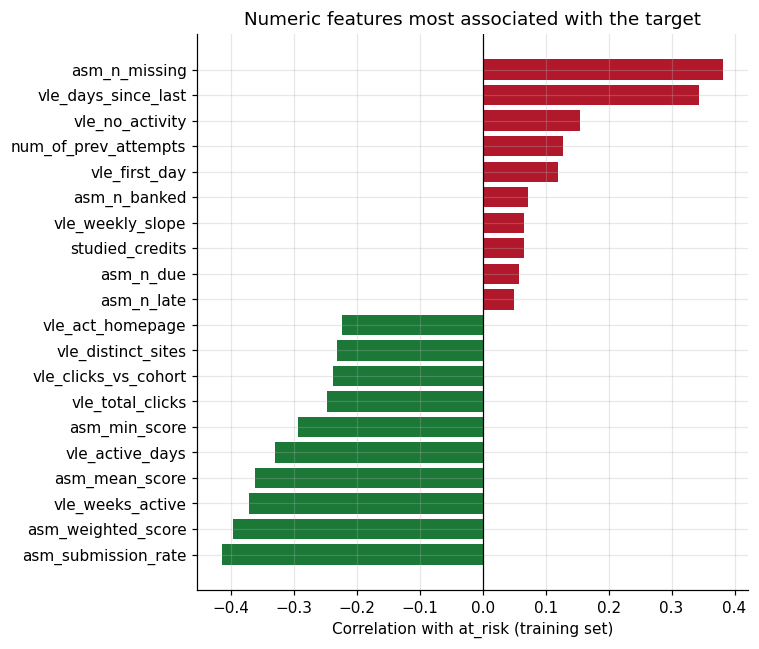

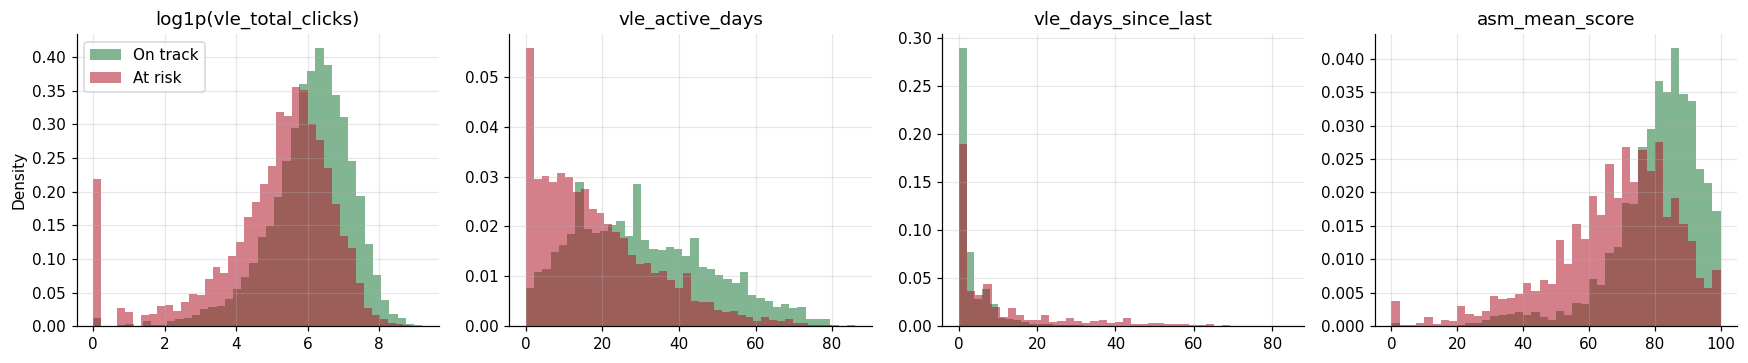

In [ ]:
correlation = train_df[NUMERIC_COLS].corrwith(train_df[TARGET]).dropna().sort_values()
strongest = pd.concat([correlation.head(10), correlation.tail(10)])

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(strongest.index, strongest.to_numpy(), color=np.where(strongest.to_numpy() < 0, "#1b7837", "#b2182b"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Correlation with at_risk (training set)")
ax.set_title("Numeric features most associated with the target")
save_figure("eda_feature_correlations")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (column, use_log) in zip(axes, [
    ("vle_total_clicks", True), ("vle_active_days", False), ("vle_days_since_last", False), ("asm_mean_score", False),
]):
    for label, colour, name in ((0, "#1b7837", "On track"), (1, "#b2182b", "At risk")):
        values = train_df.loc[train_df[TARGET] == label, column].dropna()
        ax.hist(np.log1p(values) if use_log else values, bins=40, alpha=0.55, density=True, color=colour, label=name)
    ax.set_title(f"log1p({column})" if use_log else column)
axes[0].legend()
axes[0].set_ylabel("Density")
save_figure("eda_feature_distributions")

**Interpretation.** The strongest correlations are with assessment and consistency features rather than raw volume. On the protective side, the largest are `asm_submission_rate` (about −0.41), `asm_weighted_score` (−0.40), `vle_weeks_active` (−0.37) and `asm_mean_score` (−0.36). On the risk side, the largest are `asm_n_missing` (+0.38) and the recency feature `vle_days_since_last` (+0.34). Total clicks (−0.25) is weaker than the number of weeks in which a student was active. This suggests that regular engagement matters more than how much a student clicks.

The histograms show heavy overlap between the two classes on every single feature. About a fifth of at-risk students have zero clicks, which makes them easy to flag, but across the rest of the range the two distributions largely coincide. No single feature separates the classes, and the overlap sets a ceiling on what any day-60 model can achieve. This is worth keeping in mind when the models below converge at a ROC-AUC of about 0.83–0.84.

## 6. Preprocessing

Preprocessing is wrapped in a scikit-learn `ColumnTransformer` that sits inside each model pipeline. It is therefore re-fitted on the training portion of every cross-validation fold, so no statistic (median, mean, category list) is ever computed from validation or test rows.

| Feature type | Steps | Why |
|--------------|-------|-----|
| Click counts and ratios | median imputation, `log1p`, standardisation | Counts are heavily right-skewed; the log compresses the tail so linear models and neural networks are not dominated by a few very active students |
| Other numeric | median imputation, standardisation | Puts features on one scale for logistic regression, SVM and gradient descent; missing scores (no submission yet) are imputed, and `asm_n_submitted` carries the "nothing submitted" signal |
| Categorical | "Unknown" for missing, one-hot encoding | No ordinal assumption; unseen categories at prediction time are encoded as all zeros |

Tree ensembles do not need scaling, but using one shared preprocessor keeps the comparison between models fair and the code simple.

In [ ]:
LOG_PREFIXES = (
    "vle_wk_", "vle_act_", "vle_total_clicks", "vle_distinct_sites",
    "vle_clicks_per_active_day", "vle_clicks_vs_cohort", "vle_weekly_std",
)


def numeric_transformers(numeric_cols):
    """ColumnTransformer entries for numeric features: skewed counts get a log transform."""
    count_cols = [c for c in numeric_cols if c.startswith(LOG_PREFIXES)]
    other_cols = [c for c in numeric_cols if c not in count_cols]
    count_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    other_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scale", StandardScaler()),
    ])
    return [("counts", count_pipe, count_cols), ("numeric", other_pipe, other_cols)]


def make_preprocessor(numeric_cols, categorical_cols):
    categorical_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer(
        numeric_transformers(numeric_cols) + [("categorical", categorical_pipe, categorical_cols)],
        verbose_feature_names_out=False,
    )


def make_pipeline(estimator, numeric_cols=None, categorical_cols=None):
    """Preprocessing plus estimator; the column lists default to the full feature set."""
    numeric_cols = NUMERIC_COLS if numeric_cols is None else numeric_cols
    categorical_cols = CATEGORICAL_COLS if categorical_cols is None else categorical_cols
    return Pipeline([("prep", make_preprocessor(numeric_cols, categorical_cols)), ("clf", estimator)])


preview = make_preprocessor(NUMERIC_COLS, CATEGORICAL_COLS).fit(X_train)
print(f"Raw feature columns:        {len(FEATURE_COLS)}")
print(f"Columns after encoding:     {len(preview.get_feature_names_out())}")

Raw feature columns:        54
Columns after encoding:     91


## 7. Traditional machine learning experiments

### 7.1 Evaluation helpers

Every model, traditional or deep, is scored by the same function so the numbers are directly comparable. **ROC-AUC** is the headline metric because it measures ranking quality independently of any threshold, which suits a setting where a tutor works down a ranked list. **PR-AUC**, precision, recall and F1 describe performance on the at-risk class specifically. Accuracy is reported for completeness.

In [ ]:
def evaluate(y_true, proba, threshold=0.5):
    """Threshold-dependent and threshold-free metrics for the positive (at-risk) class."""
    pred = (np.asarray(proba) >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, proba),
        "pr_auc": average_precision_score(y_true, proba),
    }


def positive_proba(model, X):
    return model.predict_proba(X)[:, 1]


def results_table(results):
    return pd.DataFrame.from_dict(results, orient="index").sort_values("roc_auc", ascending=False).round(4)


ml_models = {}        # name -> fitted pipeline
ml_val_results = {}   # name -> validation metrics


def register_ml(name, pipeline, fit_seconds):
    """Store a fitted pipeline with its validation metrics and its train/validation AUC gap."""
    ml_models[name] = pipeline
    ml_val_results[name] = {
        **evaluate(y_val, positive_proba(pipeline, X_val)),
        "train_roc_auc": roc_auc_score(y_train, positive_proba(pipeline, X_train)),
        "fit_seconds": round(fit_seconds, 1),
    }

### 7.2 Experiment ML-1: baseline models with default hyperparameters

Four algorithm families are compared, plus a dummy classifier that always predicts the class prior. The dummy sets the floor: any model that cannot beat it has learned nothing.

* **Logistic regression** is the linear, interpretable reference.
* **Random forest** is a bagged ensemble of deep trees, robust to scale and to irrelevant features.
* **Histogram gradient boosting** is a boosted ensemble, usually the strongest family on tabular data.
* **Linear SVM** is a maximum-margin linear model. An RBF kernel was not used because its training cost grows roughly quadratically with the number of rows. The SVM is wrapped in `CalibratedClassifierCV` so it produces probabilities like the other models.

In [ ]:
BASELINES = {
    "Dummy (class prior)": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=SEED),
    "Linear SVM": CalibratedClassifierCV(LinearSVC(dual=False, max_iter=5000), cv=3),
}

for name, estimator in BASELINES.items():
    pipeline = make_pipeline(estimator)
    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    register_ml(name, pipeline, time.perf_counter() - start)

display(results_table(ml_val_results))

,accuracy,precision,recall,f1,roc_auc,pr_auc,train_roc_auc,fit_seconds
Logistic Regression,0.7663,0.7833,0.6306,0.6987,0.8373,0.8227,0.8413,0.8
Hist Gradient Boosting,0.7645,0.7777,0.6329,0.6979,0.8356,0.8207,0.9029,1.9
Random Forest,0.7623,0.7836,0.6171,0.6905,0.8307,0.8159,1.0000,24.6
Linear SVM,0.7507,0.8000,0.5597,0.6586,0.8137,0.8020,0.8212,2.1
Dummy (class prior),0.5703,0.0000,0.0000,0.0000,0.5000,0.4297,0.5000,0.2


**Interpretation.** Every model clearly beats the dummy, which scores a ROC-AUC of 0.500. Logistic regression is best on validation ROC-AUC (0.837), followed closely by gradient boosting (0.836), random forest (0.831) and the linear SVM (0.814). The best model beats the dummy by 0.337.

The train/validation gap tells the overfitting story. The default random forest scores 1.000 on its own training data and 0.831 on validation, which is memorisation rather than skill. Gradient boosting's gap is 0.903 against 0.836. Logistic regression's gap is only 0.004 (0.841 against 0.837). A linear model matching the ensembles means that, after the log transform and scaling, most of the usable signal is close to linear. The extra flexibility of the trees is spent mostly on fitting noise.

### 7.3 Experiment ML-2: hyperparameter tuning

Each family is tuned with a randomised search over the ranges below. Randomised search is used instead of a grid because it covers wide, continuous ranges with far fewer fits. Cross-validation uses `StratifiedGroupKFold`, so folds are stratified on the target and still keep every student inside a single fold. The search sees the training set only.

| Model | Hyperparameters searched | What they control |
|-------|--------------------------|-------------------|
| Logistic regression | `C` (log-uniform 0.001 to 100), `class_weight` | Strength of L2 regularisation; whether errors on the two classes are weighted equally |
| Random forest | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features` | Ensemble size; tree complexity; decorrelation between trees |
| Hist gradient boosting | `learning_rate`, `max_iter`, `max_leaf_nodes`, `min_samples_leaf`, `l2_regularization` | Step size against number of boosting rounds; tree complexity; shrinkage of leaf values |
| Linear SVM | `C` (log-uniform 0.001 to 10) | Width of the margin against training errors |

In [ ]:
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)

SEARCH_SPACES = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000),
        {"clf__C": loguniform(1e-3, 1e2), "clf__class_weight": [None, "balanced"]},
        N_ITER["lr"],
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=SEED),
        {
            "clf__n_estimators": [200, 300],
            "clf__max_depth": [None, 8, 12, 20],
            "clf__min_samples_leaf": randint(1, 20),
            "clf__max_features": ["sqrt", 0.3, 0.5],
        },
        N_ITER["rf"],
    ),
    "Hist Gradient Boosting": (
        HistGradientBoostingClassifier(random_state=SEED),
        {
            "clf__learning_rate": loguniform(0.02, 0.3),
            "clf__max_iter": randint(100, 500),
            "clf__max_leaf_nodes": randint(8, 64),
            "clf__min_samples_leaf": randint(10, 100),
            "clf__l2_regularization": loguniform(1e-3, 10),
        },
        N_ITER["hgb"],
    ),
    "Linear SVM": (
        CalibratedClassifierCV(LinearSVC(dual=False, max_iter=5000), cv=3),
        {"clf__estimator__C": loguniform(1e-3, 10)},
        N_ITER["svm"],
    ),
}

searches = {}
tuning_rows = {}
for name, (estimator, space, n_iter) in SEARCH_SPACES.items():
    search = RandomizedSearchCV(
        make_pipeline(estimator),
        space,
        n_iter=n_iter,
        scoring="roc_auc",
        cv=cv,
        random_state=SEED,
        n_jobs=-1,
        return_train_score=True,
    )
    start = time.perf_counter()
    search.fit(X_train, y_train, groups=groups_train)
    elapsed = time.perf_counter() - start

    searches[name] = search
    register_ml(f"{name} (tuned)", search.best_estimator_, elapsed)
    best = search.best_index_
    tuning_rows[name] = {
        "cv_roc_auc": search.cv_results_["mean_test_score"][best],
        "cv_std": search.cv_results_["std_test_score"][best],
        "cv_train_roc_auc": search.cv_results_["mean_train_score"][best],
        "candidates": n_iter,
        "search_seconds": round(elapsed, 1),
        "best_params": {k.replace("clf__", ""): (round(v, 4) if isinstance(v, float) else v)
                        for k, v in search.best_params_.items()},
    }
    print(f"{name:<24} best CV ROC-AUC = {search.best_score_:.4f}  ({elapsed:.0f}s)")

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame.from_dict(tuning_rows, orient="index").round(4))
display(results_table(ml_val_results))

Logistic Regression      best CV ROC-AUC = 0.8357  (21s)
Random Forest            best CV ROC-AUC = 0.8319  (822s)
Hist Gradient Boosting   best CV ROC-AUC = 0.8350  (119s)
Linear SVM               best CV ROC-AUC = 0.8292  (23s)


,cv_roc_auc,cv_std,cv_train_roc_auc,candidates,search_seconds,best_params
Logistic Regression,0.8357,0.0036,0.8422,12,20.9,"{'C': 0.0746, 'class_weight': None}"
Random Forest,0.8319,0.0039,0.9669,10,822.1,"{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 7, 'n_estimators': 300}"
Hist Gradient Boosting,0.8350,0.0040,0.8726,20,119.3,"{'l2_regularization': 8.5689, 'learning_rate': 0.0708, 'max_iter': 406, 'max_leaf_nodes': 14, 'min_samples_leaf': 30}"
Linear SVM,0.8292,0.0044,0.8342,8,22.9,{'estimator__C': 0.0017}


,accuracy,precision,recall,f1,roc_auc,pr_auc,train_roc_auc,fit_seconds
Logistic Regression,0.7663,0.7833,0.6306,0.6987,0.8373,0.8227,0.8413,0.8
Logistic Regression (tuned),0.7658,0.7805,0.6329,0.6990,0.8372,0.8227,0.8411,20.9
Hist Gradient Boosting (tuned),0.7670,0.7801,0.6376,0.7017,0.8358,0.8216,0.8620,119.3
Hist Gradient Boosting,0.7645,0.7777,0.6329,0.6979,0.8356,0.8207,0.9029,1.9
Random Forest (tuned),0.7615,0.7849,0.6130,0.6884,0.8326,0.8176,0.9661,822.1
Random Forest,0.7623,0.7836,0.6171,0.6905,0.8307,0.8159,1.0000,24.6
Linear SVM (tuned),0.7535,0.7898,0.5808,0.6694,0.8294,0.8149,0.8334,22.9
Linear SVM,0.7507,0.8000,0.5597,0.6586,0.8137,0.8020,0.8212,2.1
Dummy (class prior),0.5703,0.0000,0.0000,0.0000,0.5000,0.4297,0.5000,0.2


**Interpretation.** Tuning made little difference, which is itself a finding. The validation ROC-AUC changes are −0.0001 for logistic regression, +0.0002 for gradient boosting, +0.0019 for random forest and +0.0157 for the linear SVM. Only the SVM gained meaningfully, by choosing a very small `C` (0.0017), that is, much stronger regularisation than the default.

The chosen hyperparameters all point the same way: regularise. Gradient boosting chose small trees (14 leaves) with heavy L2 regularisation (8.6), which cut its training ROC-AUC from 0.903 to 0.862 without any loss on validation. Random forest chose `min_samples_leaf = 7`, which cut its training score from 1.000 to 0.966. Logistic regression settled on `C ≈ 0.07` with no class weighting.

The cross-validated and validation scores agree to within 0.002 for every family (for example 0.8350 against 0.8358 for gradient boosting). This indicates that the validation set is representative and that model selection on it is reliable.

The plot below shows how sensitive gradient boosting is to its two most important hyperparameters. Each point is one candidate from the search.

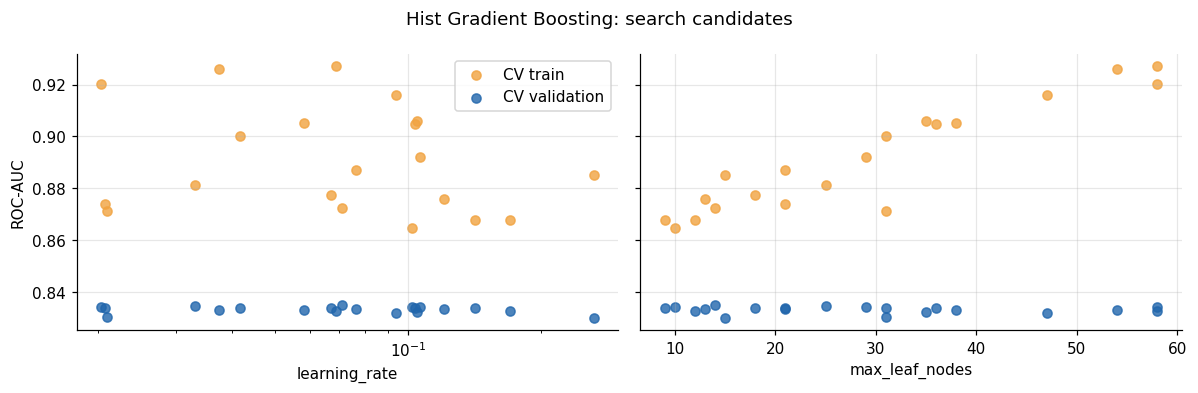

In [ ]:
hgb_results = pd.DataFrame(searches["Hist Gradient Boosting"].cv_results_)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, parameter in zip(axes, ("param_clf__learning_rate", "param_clf__max_leaf_nodes")):
    x = hgb_results[parameter].astype(float)
    ax.scatter(x, hgb_results["mean_train_score"], label="CV train", color="#f1a340", alpha=0.8)
    ax.scatter(x, hgb_results["mean_test_score"], label="CV validation", color="#2166ac", alpha=0.8)
    ax.set_xlabel(parameter.replace("param_clf__", ""))
axes[0].set_xscale("log")
axes[0].set_ylabel("ROC-AUC")
axes[0].legend()
fig.suptitle("Hist Gradient Boosting: search candidates")
save_figure("ml_hgb_search")

**Interpretation.** Validation ROC-AUC barely moves across the search: every one of the 20 candidates falls between 0.830 and 0.835, whatever its learning rate or tree size. Training ROC-AUC, by contrast, rises from about 0.865 with 10 leaves to about 0.925 with 55–60 leaves. A flat validation cloud beneath a rising training cloud is the signature of extra capacity being spent on memorisation. On this feature set, gradient boosting is insensitive to its hyperparameters, and the sensible choice is the simplest, most regularised configuration.

### 7.4 Learning curve for the best traditional model

A learning curve refits the model on growing fractions of the training data. It answers two questions: is the model limited by bias or by variance, and would collecting more students help?

Best traditional model on validation ROC-AUC: Logistic Regression


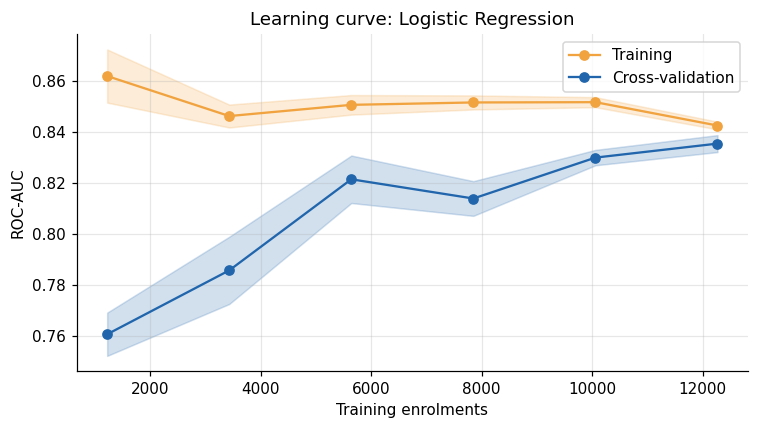

In [ ]:
ml_table = results_table(ml_val_results).drop(index="Dummy (class prior)")
best_ml_name = ml_table["roc_auc"].idxmax()
best_ml_model = ml_models[best_ml_name]
print(f"Best traditional model on validation ROC-AUC: {best_ml_name}")

sizes, train_scores, cv_scores = learning_curve(
    clone(best_ml_model),
    X_train,
    y_train,
    groups=groups_train,
    train_sizes=np.linspace(0.1, 1.0, 6),
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
)

fig, ax = plt.subplots(figsize=(7, 4))
for scores, label, colour in ((train_scores, "Training", "#f1a340"), (cv_scores, "Cross-validation", "#2166ac")):
    mean, std = scores.mean(axis=1), scores.std(axis=1)
    ax.plot(sizes, mean, "o-", color=colour, label=label)
    ax.fill_between(sizes, mean - std, mean + std, color=colour, alpha=0.2)
ax.set_xlabel("Training enrolments")
ax.set_ylabel("ROC-AUC")
ax.set_title(f"Learning curve: {best_ml_name}")
ax.legend()
save_figure("ml_learning_curve")

**Interpretation.** With about 1,200 training enrolments, the cross-validation ROC-AUC is 0.76 and the training score is 0.86, a gap of 0.10. As the training set grows to about 12,300 enrolments (two-thirds of the training set, because of 3-fold CV), the cross-validation curve rises to 0.835. Over the same range the training curve falls to 0.843, closing the gap to under 0.01.

The two curves have almost met. This means logistic regression is now limited mainly by bias, that is, by the information in its features, rather than by variance. The cross-validation curve is still creeping upwards at the right-hand edge, so more students would give a small further gain, but most of the benefit of more data has already been realised. Larger improvements would need better features or a more flexible model. Section 8 shows that the neural networks add very little, which points back to the features themselves.

### 7.5 Experiment ML-3: which feature families matter? (ablation)

The same gradient-boosting model is trained on different subsets of features. This measures the value of the feature engineering directly, and it shows how much of the predictive power comes from who the student *is* compared with what the student *does*.

,n_features,accuracy,precision,recall,f1,roc_auc,pr_auc
Background only (known at day 0),13,0.6209,0.5914,0.3806,0.4631,0.6487,0.5658
VLE engagement only,30,0.7072,0.7159,0.5281,0.6078,0.7646,0.7417
Assessment only,11,0.7469,0.7872,0.5632,0.6567,0.8100,0.7925
Background + VLE,43,0.7223,0.7382,0.5480,0.6290,0.7880,0.7657
Background + assessment,24,0.7542,0.7844,0.5902,0.6736,0.8158,0.8013
All features,54,0.7645,0.7777,0.6329,0.6979,0.8356,0.8207


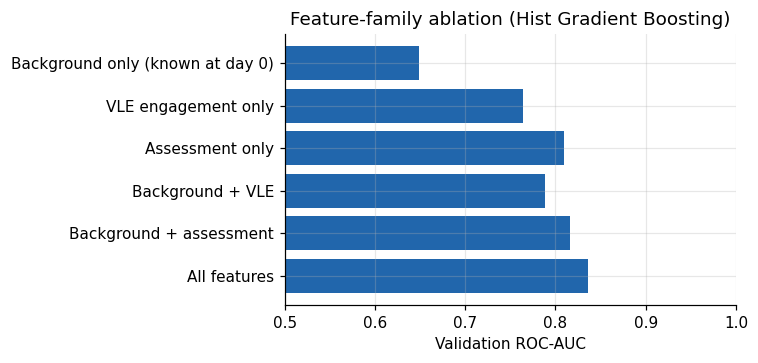

In [ ]:
ABLATIONS = {
    "Background only (known at day 0)": (GROUPS["background"], CATEGORICAL_COLS),
    "VLE engagement only": (GROUPS["vle"], []),
    "Assessment only": (GROUPS["assessment"], []),
    "Background + VLE": (GROUPS["background"] + GROUPS["vle"], CATEGORICAL_COLS),
    "Background + assessment": (GROUPS["background"] + GROUPS["assessment"], CATEGORICAL_COLS),
    "All features": (NUMERIC_COLS, CATEGORICAL_COLS),
}

ablation_rows = {}
for name, (numeric_cols, categorical_cols) in ABLATIONS.items():
    pipeline = make_pipeline(HistGradientBoostingClassifier(random_state=SEED), numeric_cols, categorical_cols)
    pipeline.fit(X_train, y_train)
    ablation_rows[name] = {
        "n_features": len(numeric_cols) + len(categorical_cols),
        **evaluate(y_val, positive_proba(pipeline, X_val)),
    }
ablation_table = pd.DataFrame.from_dict(ablation_rows, orient="index").round(4)
display(ablation_table)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(ablation_table.index[::-1], ablation_table["roc_auc"][::-1], color="#2166ac")
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("Validation ROC-AUC")
ax.set_title("Feature-family ablation (Hist Gradient Boosting)")
save_figure("ml_feature_ablation")

**Interpretation.** Using background features only, which is everything the university knows on enrolment day, gradient boosting reaches a ROC-AUC of just 0.649. Behaviour is far more informative. Early assessment results alone reach 0.810, and VLE engagement alone reaches 0.765.

The two behavioural families are complementary rather than redundant. Adding VLE features to background plus assessment raises ROC-AUC from 0.816 to 0.836, and recall at a threshold of 0.5 rises from 0.590 to 0.633. Each family therefore captures something the other misses: assessment features measure performance, while VLE features measure engagement and its recency.

This table is the main evidence for the value of the feature engineering. Who a student *is* explains much less than what the student *does* in the first two months.

### 7.6 Experiment ML-4: how early can we predict? (cutoff sensitivity)

The whole feature pipeline is rebuilt for several prediction days. Note that the cohort itself changes with the cutoff, because students who have already withdrawn are removed. The scores are therefore not measured on identical students, and the table reports cohort size and at-risk share next to each score so this is visible.

,cohort_size,at_risk_share,accuracy,precision,recall,f1,roc_auc,pr_auc
cutoff_day,,,,,,,,
0,29262,0.4783,0.6648,0.6582,0.6188,0.6379,0.7213,0.6951
30,27450,0.4397,0.7271,0.7231,0.5972,0.6541,0.7868,0.7647
60,26353,0.4163,0.7645,0.7777,0.6329,0.6979,0.8356,0.8207
90,25558,0.3981,0.7967,0.8045,0.6484,0.7181,0.8586,0.8404
120,24775,0.3790,0.8231,0.8170,0.6978,0.7527,0.8940,0.8717


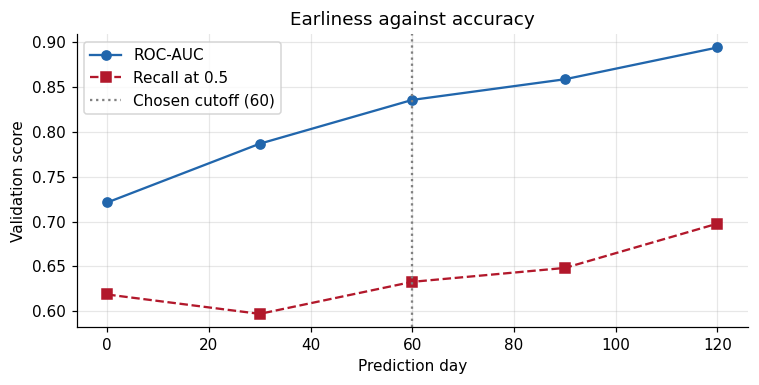

In [ ]:
cutoff_rows = {}
for cutoff in (0, 30, 60, 90, 120):
    cutoff_features = build_features(tables, cutoff)
    numeric_cols = numeric_feature_columns(cutoff_features)
    tr, va, _ = split_by_student(cutoff_features)
    pipeline = make_pipeline(HistGradientBoostingClassifier(random_state=SEED), numeric_cols, CATEGORICAL_COLS)
    pipeline.fit(tr[numeric_cols + CATEGORICAL_COLS], tr[TARGET])
    proba = positive_proba(pipeline, va[numeric_cols + CATEGORICAL_COLS])
    cutoff_rows[cutoff] = {
        "cohort_size": len(cutoff_features),
        "at_risk_share": cutoff_features[TARGET].mean(),
        **evaluate(va[TARGET].to_numpy(), proba),
    }
cutoff_table = pd.DataFrame.from_dict(cutoff_rows, orient="index").rename_axis("cutoff_day").round(4)
display(cutoff_table)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(cutoff_table.index, cutoff_table["roc_auc"], "o-", color="#2166ac", label="ROC-AUC")
ax.plot(cutoff_table.index, cutoff_table["recall"], "s--", color="#b2182b", label="Recall at 0.5")
ax.axvline(CUTOFF_DAY, color="grey", linestyle=":", label=f"Chosen cutoff ({CUTOFF_DAY})")
ax.set_xlabel("Prediction day")
ax.set_ylabel("Validation score")
ax.set_title("Earliness against accuracy")
ax.legend()
save_figure("ml_cutoff_sensitivity")
del cutoff_features

**Interpretation.** ROC-AUC rises steadily with the prediction day: 0.721 at day 0, 0.787 at day 30, 0.836 at day 60, 0.859 at day 90 and 0.894 at day 120. The largest gains come in the first two months (+0.066 and then +0.049 per 30 days). The gain then slows (+0.023 between days 60 and 90) before rising again by day 120, when the second round of assessments becomes visible.

The cohort shrinks at the same time, from 29,262 to 24,775 enrolments, as students leave. The later scores are therefore measured on a population that is easier to classify and that contains fewer of the students who most need help.

Day 0 scores 0.721, above the background-only ablation (0.649). Pre-start VLE activity in the `vle_wk_pre` feature already carries signal, as do the extra students in the larger day-0 cohort, many of whom never engage.

Day 60 is a reasonable compromise. It recovers about two-thirds of the gain between day 0 and day 120, and it leaves roughly three-quarters of a typical 260-day module for intervention. A university could also run the model at several checkpoints, using the early versions as a coarse screen and refreshing the scores as evidence accumulates.

## 8. Deep learning experiments

### 8.1 Input pipelines with `tf.data`

Neural networks need dense, scaled numeric tensors. Two representations of the same splits are prepared:

* **Dense input** for the Sequential models: the output of the same preprocessor used in Section 6 (log, scale, one-hot), so the MLPs and the traditional models see identical information.
* **Dictionary input** for the Functional model: scaled numeric features in one tensor, plus one integer-coded tensor per categorical feature so each can be passed through its own embedding layer.

`make_dataset` builds the `tf.data` pipeline: slice the arrays into examples, cache them in memory, shuffle the full training set with a fresh order each epoch, batch, and prefetch so the next batch is prepared while the current one trains.

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE


def make_dataset(inputs, labels, batch_size=256, training=False):
    """tf.data pipeline over an array, or a dict of arrays, and its labels."""
    labels = np.asarray(labels, dtype="float32").reshape(-1, 1)
    dataset = tf.data.Dataset.from_tensor_slices((inputs, labels)).cache()
    if training:
        dataset = dataset.shuffle(buffer_size=len(labels), seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(batch_size).prefetch(AUTOTUNE)


# Dense representation (one-hot categoricals) for the Sequential MLPs.
dl_preprocessor = make_preprocessor(NUMERIC_COLS, CATEGORICAL_COLS).fit(X_train)
dense_inputs = {split: dl_preprocessor.transform(X).astype("float32") for split, X in X_splits.items()}
INPUT_DIM = dense_inputs["train"].shape[1]

# Dictionary representation (integer-coded categoricals) for the embedding model.
numeric_prep = ColumnTransformer(numeric_transformers(NUMERIC_COLS)).fit(X_train)
category_encoder = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
]).fit(X_train[CATEGORICAL_COLS])
CARDINALITIES = {
    column: len(categories) + 1     # index 0 is reserved for categories unseen in training
    for column, categories in zip(CATEGORICAL_COLS, category_encoder.named_steps["ordinal"].categories_)
}


def to_embedding_inputs(X):
    codes = category_encoder.transform(X[CATEGORICAL_COLS]).astype("int32") + 1
    inputs = {column: codes[:, [i]] for i, column in enumerate(CATEGORICAL_COLS)}
    inputs["numeric"] = numeric_prep.transform(X).astype("float32")
    return inputs


dl_inputs = {
    "dense": dense_inputs,
    "embedding": {split: to_embedding_inputs(X) for split, X in X_splits.items()},
}

example_x, example_y = next(iter(make_dataset(dense_inputs["train"], y_train, training=True)))
print(f"Dense input width: {INPUT_DIM}")
print(f"One training batch: features {example_x.shape}, labels {example_y.shape}")
print(f"Embedding cardinalities: {CARDINALITIES}")

Dense input width: 91
One training batch: features (256, 91), labels (256, 1)
Embedding cardinalities: {'code_module': 8, 'pres_semester': 3, 'gender': 3, 'region': 14, 'highest_education': 6, 'imd_band': 12, 'age_band': 4, 'disability': 3}


### 8.2 Model builders and training loop

`build_mlp` creates a Sequential network whose depth, width and regularisation are arguments, so every experiment below is one function call with different settings. All models end in a single sigmoid unit and minimise binary cross-entropy.

Training uses two callbacks. **Early stopping** watches validation ROC-AUC and restores the weights from the best epoch, which is itself a form of regularisation. **ReduceLROnPlateau** halves the learning rate when validation loss stops improving, which lets training settle into a minimum.

In [ ]:
def make_optimizer(name, learning_rate):
    if name == "adam":
        return keras.optimizers.Adam(learning_rate=learning_rate)
    if name == "rmsprop":
        return keras.optimizers.RMSprop(learning_rate=learning_rate)
    if name == "sgd":
        return keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9, nesterov=True)
    raise ValueError(f"Unknown optimizer: {name}")


def compile_model(model, optimizer="adam", learning_rate=1e-3):
    model.compile(
        optimizer=make_optimizer(optimizer, learning_rate),
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="auc"), keras.metrics.BinaryAccuracy(name="accuracy")],
    )
    return model


def dense_block(x, units, dropout, l2, batch_norm):
    """Dense -> (BatchNorm) -> ReLU -> (Dropout), shared by both architectures."""
    x = layers.Dense(units, kernel_regularizer=regularizers.l2(l2) if l2 else None)(x)
    if batch_norm:
        x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    if dropout:
        x = layers.Dropout(dropout)(x)
    return x


def build_mlp(input_dim, hidden=(64, 32), dropout=0.0, l2=0.0, batch_norm=False,
              optimizer="adam", learning_rate=1e-3, name="mlp"):
    """Sequential multilayer perceptron on the dense (one-hot) input."""
    model = keras.Sequential(name=name)
    model.add(keras.Input(shape=(input_dim,)))
    for units in hidden:
        model.add(layers.Dense(units, kernel_regularizer=regularizers.l2(l2) if l2 else None))
        if batch_norm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        if dropout:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    return compile_model(model, optimizer, learning_rate)


def build_embedding_model(cardinalities, n_numeric, hidden=(128, 64), dropout=0.3, l2=1e-4,
                          batch_norm=True, optimizer="adam", learning_rate=1e-3, name="embedding_net"):
    """Functional model: one learned embedding per categorical feature, joined to the numeric features."""
    inputs, branches = {}, []
    for column, cardinality in cardinalities.items():
        inputs[column] = keras.Input(shape=(1,), dtype="int32", name=column)
        embedding_dim = min(8, max(2, (cardinality + 1) // 2))
        embedded = layers.Embedding(cardinality + 1, embedding_dim, name=f"embed_{column}")(inputs[column])
        branches.append(layers.Flatten()(embedded))
    inputs["numeric"] = keras.Input(shape=(n_numeric,), name="numeric")

    x = layers.Concatenate()(branches + [inputs["numeric"]])
    for units in hidden:
        x = dense_block(x, units, dropout, l2, batch_norm)
    output = layers.Dense(1, activation="sigmoid", name="at_risk")(x)
    return compile_model(keras.Model(inputs=inputs, outputs=output, name=name), optimizer, learning_rate)


dl_runs = {}          # name -> model, history, input kind, batch size, config
dl_val_results = {}   # name -> validation metrics


def predict_dl(name, split):
    run = dl_runs[name]
    dataset = make_dataset(dl_inputs[run["kind"]][split], y_splits[split], run["batch_size"])
    return run["model"].predict(dataset, verbose=0).ravel()


def run_dl_experiment(name, model, kind="dense", batch_size=256, patience=10, config=None):
    """Train with early stopping on validation AUC, then record history and validation metrics."""
    train_ds = make_dataset(dl_inputs[kind]["train"], y_train, batch_size, training=True)
    val_ds = make_dataset(dl_inputs[kind]["val"], y_val, batch_size)
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5),
    ]
    start = time.perf_counter()
    history = model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS, callbacks=callbacks, verbose=0)
    elapsed = time.perf_counter() - start

    dl_runs[name] = {"model": model, "history": history.history, "kind": kind,
                     "batch_size": batch_size, "config": config or {}}
    best_epoch = int(np.argmax(history.history["val_auc"]))
    dl_val_results[name] = {
        **evaluate(y_val, predict_dl(name, "val")),
        "train_roc_auc": history.history["auc"][best_epoch],
        "best_epoch": best_epoch + 1,
        "epochs_run": len(history.history["loss"]),
        "parameters": model.count_params(),
        "fit_seconds": round(elapsed, 1),
    }
    print(f"{name:<34} val ROC-AUC = {dl_val_results[name]['roc_auc']:.4f}  "
          f"(best epoch {best_epoch + 1} of {len(history.history['loss'])}, {elapsed:.0f}s)")
    return dl_val_results[name]


def plot_histories(names, filename):
    """Loss and ROC-AUC per epoch, training against validation, one row per experiment."""
    fig, axes = plt.subplots(len(names), 2, figsize=(11, 3.2 * len(names)), squeeze=False)
    for row, name in zip(axes, names):
        history = dl_runs[name]["history"]
        epochs = np.arange(1, len(history["loss"]) + 1)
        best_epoch = int(np.argmax(history["val_auc"])) + 1
        for ax, metric, label in zip(row, ("loss", "auc"), ("Binary cross-entropy", "ROC-AUC")):
            ax.plot(epochs, history[metric], color="#f1a340", label="Training")
            ax.plot(epochs, history[f"val_{metric}"], color="#2166ac", label="Validation")
            ax.axvline(best_epoch, color="grey", linestyle=":", label="Best epoch (weights restored)")
            ax.set_title(f"{name}: {label}")
            ax.set_xlabel("Epoch")
        row[0].legend(fontsize=8)
    save_figure(filename)

### 8.3 Experiments DL-1 to DL-3: capacity and regularisation

Three Sequential models isolate the effect of capacity and of regularisation:

| Experiment | Architecture | Regularisation | Question |
|------------|--------------|----------------|----------|
| DL-1 | 64-32 | none | What does a small plain MLP achieve? |
| DL-2 | 256-128-64 | none | Does several times the capacity help, or does it overfit? |
| DL-3 | 256-128-64 | dropout 0.3, L2 1e-4, batch normalisation | Does regularisation recover what DL-2 loses? |

Note that the training curves are measured with dropout active and the validation curves with it switched off, so for DL-3 the training loss can sit *above* the validation loss. That is expected and is not a bug. For the same reason, `train_roc_auc` in the deep learning tables is the running estimate Keras reports during the best epoch, so treat it as approximate.

DL-1 small MLP                     val ROC-AUC = 0.8359  (best epoch 12 of 22, 10s)
DL-2 large MLP, no regularisation  val ROC-AUC = 0.8408  (best epoch 3 of 13, 10s)
DL-3 large MLP, regularised        val ROC-AUC = 0.8400  (best epoch 10 of 20, 20s)


Model: "dl3_regularised_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 256)            │        23,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 197,893 (773.02 KB)

 Trainable params: 65,665 (256.50 KB)

 Non-trainable params: 896 (3.50 KB)

 Optimizer params: 131,332 (513.02 KB)

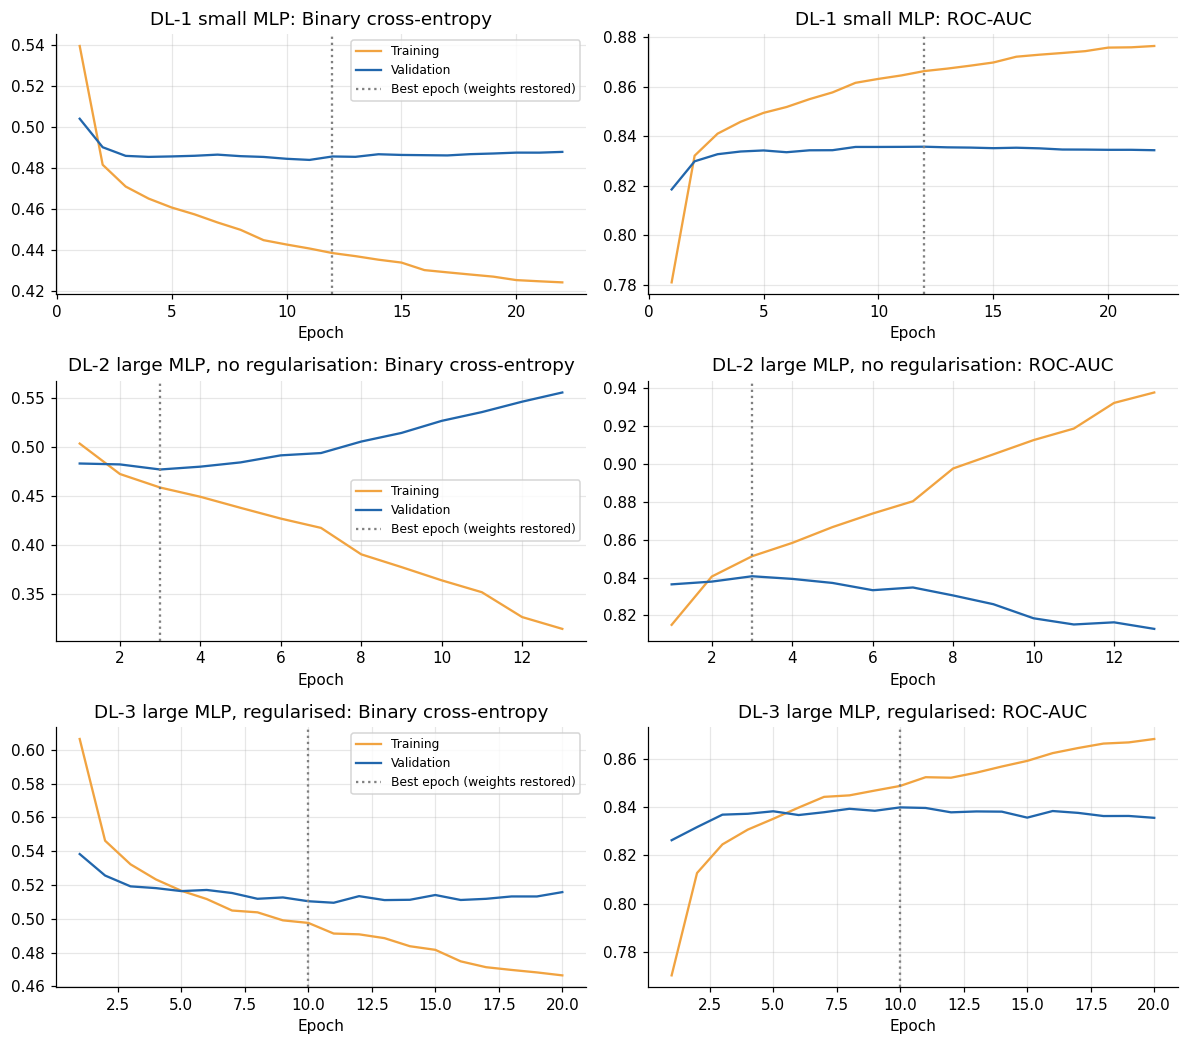

,accuracy,precision,recall,f1,roc_auc,pr_auc,train_roc_auc,best_epoch,epochs_run,parameters,fit_seconds
"DL-2 large MLP, no regularisation",0.7691,0.7838,0.6388,0.7039,0.8408,0.8261,0.8513,3,13,64769,10.2
"DL-3 large MLP, regularised",0.7698,0.7763,0.6522,0.7089,0.8400,0.8255,0.8488,10,20,66561,19.8
DL-1 small MLP,0.7650,0.7776,0.6347,0.6989,0.8359,0.8207,0.8664,12,22,8001,10.0


In [ ]:
keras.utils.set_random_seed(SEED)
run_dl_experiment("DL-1 small MLP", build_mlp(INPUT_DIM, hidden=(64, 32), name="dl1_small_mlp"))

keras.utils.set_random_seed(SEED)
run_dl_experiment("DL-2 large MLP, no regularisation",
                  build_mlp(INPUT_DIM, hidden=(256, 128, 64), name="dl2_large_mlp"))

keras.utils.set_random_seed(SEED)
run_dl_experiment("DL-3 large MLP, regularised",
                  build_mlp(INPUT_DIM, hidden=(256, 128, 64), dropout=0.3, l2=1e-4, batch_norm=True,
                            name="dl3_regularised_mlp"))

dl_runs["DL-3 large MLP, regularised"]["model"].summary()
plot_histories(["DL-1 small MLP", "DL-2 large MLP, no regularisation", "DL-3 large MLP, regularised"],
               "dl_learning_curves_capacity")
display(results_table(dl_val_results))

**Interpretation.** The three models show three distinct training patterns.

* **DL-1 (small, no regularisation).** Validation loss reaches about 0.485 by epoch 3 and then stays flat. Training loss keeps falling from 0.47 to 0.42, so a gap opens, but validation performance does not degrade. The best epoch is 12, with a validation ROC-AUC of 0.836.
* **DL-2 (large, no regularisation)** shows the classic overfitting pattern. Validation loss reaches its minimum (0.477) at epoch 3, then rises steadily to 0.555 by epoch 13 while training loss falls to 0.31. Training ROC-AUC climbs towards 0.94 while validation ROC-AUC drops from 0.841 to 0.813. Early stopping restores the epoch-3 weights, which is why DL-2's reported score (0.841) is good despite the overfitting visible in its curves.
* **DL-3 (large, with dropout, L2 and batch normalisation).** The curves stay much closer together, and the best epoch arrives later (epoch 10). For the first five epochs, training loss sits *above* validation loss, because dropout is active only during training. Validation loss is higher than DL-1's in absolute terms because the L2 penalty is included in the reported loss, but the ranking quality (validation ROC-AUC 0.840) matches DL-2.

The best validation scores are almost identical: 0.836, 0.841 and 0.840. Capacity is not the limiting factor on this dataset. Early stopping already prevented the damage that DL-2's curves show, and explicit regularisation mainly makes training more stable and less dependent on catching the right epoch.

### 8.4 Experiment DL-4: random search over architecture and optimisation

A random search samples configurations from the space below. Each trial is trained with the same early-stopping rule, so the number of epochs is tuned implicitly.

| Hyperparameter | Values |
|----------------|--------|
| Hidden layers | (64, 32), (128, 64), (256, 128), (128, 64, 32), (256, 128, 64) |
| Dropout | 0.1, 0.2, 0.3, 0.4, 0.5 |
| L2 penalty | 0, 1e-5, 1e-4, 1e-3 |
| Batch normalisation | on, off |
| Optimiser | Adam, RMSprop, SGD with Nesterov momentum |
| Learning rate | 3e-4, 1e-3, 3e-3 |
| Batch size | 128, 256, 512 |

DL-4 search trial 01               val ROC-AUC = 0.8406  (best epoch 11 of 19, 12s)
DL-4 search trial 02               val ROC-AUC = 0.8330  (best epoch 80 of 80, 29s)


DL-4 search trial 03               val ROC-AUC = 0.8272  (best epoch 80 of 80, 50s)
DL-4 search trial 04               val ROC-AUC = 0.8398  (best epoch 12 of 20, 7s)


DL-4 search trial 05               val ROC-AUC = 0.8408  (best epoch 11 of 19, 14s)
DL-4 search trial 06               val ROC-AUC = 0.8382  (best epoch 71 of 79, 26s)
DL-4 search trial 07               val ROC-AUC = 0.8384  (best epoch 4 of 12, 5s)
DL-4 search trial 08               val ROC-AUC = 0.8406  (best epoch 19 of 27, 23s)
DL-4 search trial 09               val ROC-AUC = 0.8407  (best epoch 44 of 52, 33s)
DL-4 search trial 10               val ROC-AUC = 0.8411  (best epoch 24 of 32, 26s)


,hidden,dropout,l2,batch_norm,optimizer,learning_rate,batch_size,val_roc_auc,train_roc_auc,best_epoch,parameters
DL-4 search trial 10,"(256, 128, 64)",0.3,0.0000,False,rmsprop,0.0003,256,0.8411,0.8546,24,64769
DL-4 search trial 05,"(256, 128)",0.3,0.0000,True,adam,0.0010,512,0.8408,0.8530,11,58113
DL-4 search trial 09,"(256, 128)",0.1,0.0001,False,sgd,0.0030,256,0.8407,0.8537,44,56577
DL-4 search trial 01,"(64, 32)",0.4,0.0001,True,rmsprop,0.0030,128,0.8406,0.8433,11,8385
DL-4 search trial 08,"(128, 64, 32)",0.4,0.0000,True,rmsprop,0.0010,128,0.8406,0.8494,19,23041
DL-4 search trial 04,"(128, 64)",0.1,0.0010,False,rmsprop,0.0010,512,0.8398,0.8542,12,20097
DL-4 search trial 07,"(128, 64, 32)",0.2,0.0000,False,rmsprop,0.0030,512,0.8384,0.8397,4,22145
DL-4 search trial 06,"(64, 32)",0.5,0.0010,True,rmsprop,0.0003,512,0.8382,0.8395,71,8385
DL-4 search trial 02,"(128, 64, 32)",0.2,0.0000,False,sgd,0.0030,512,0.8330,0.8308,80,22145
DL-4 search trial 03,"(128, 64, 32)",0.4,0.0001,True,sgd,0.0010,256,0.8272,0.8125,80,23041


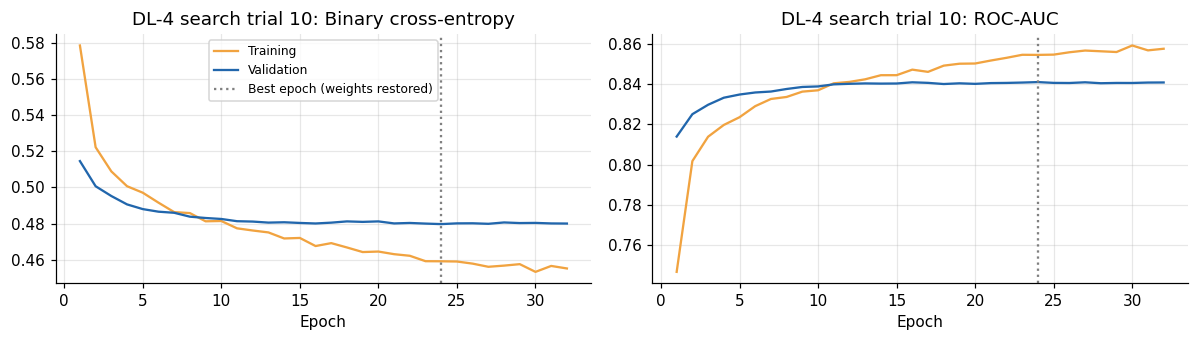

In [ ]:
DL_SEARCH_SPACE = {
    "hidden": [(64, 32), (128, 64), (256, 128), (128, 64, 32), (256, 128, 64)],
    "dropout": [0.1, 0.2, 0.3, 0.4, 0.5],
    "l2": [0.0, 1e-5, 1e-4, 1e-3],
    "batch_norm": [True, False],
    "optimizer": ["adam", "rmsprop", "sgd"],
    "learning_rate": [3e-4, 1e-3, 3e-3],
    "batch_size": [128, 256, 512],
}

search_rng = np.random.default_rng(SEED)
for trial in range(1, N_DL_TRIALS + 1):
    config = {key: values[int(search_rng.integers(len(values)))] for key, values in DL_SEARCH_SPACE.items()}
    keras.utils.set_random_seed(SEED)
    model = build_mlp(
        INPUT_DIM,
        hidden=config["hidden"],
        dropout=config["dropout"],
        l2=config["l2"],
        batch_norm=config["batch_norm"],
        optimizer=config["optimizer"],
        learning_rate=config["learning_rate"],
        name=f"dl4_trial_{trial:02d}",
    )
    run_dl_experiment(f"DL-4 search trial {trial:02d}", model, batch_size=config["batch_size"],
                      patience=8, config=config)

search_names = [name for name in dl_runs if name.startswith("DL-4")]
dl_search_table = pd.DataFrame([
    {**dl_runs[name]["config"],
     "val_roc_auc": dl_val_results[name]["roc_auc"],
     "train_roc_auc": dl_val_results[name]["train_roc_auc"],
     "best_epoch": dl_val_results[name]["best_epoch"],
     "parameters": dl_val_results[name]["parameters"]}
    for name in search_names
], index=search_names).sort_values("val_roc_auc", ascending=False)
display(dl_search_table.round(4))

best_search_name = dl_search_table.index[0]
best_config = dl_runs[best_search_name]["config"]
plot_histories([best_search_name], "dl_learning_curve_best_search")

**Interpretation.** The ten trials span validation ROC-AUC from 0.827 to 0.841, a range of 0.014. The top six trials fall within 0.0013 of one another. The best, trial 10, uses three hidden layers (256-128-64), dropout of 0.3, no L2 penalty, RMSprop and a learning rate of 3e-4. Its learning curves (above) show training and validation loss tracking each other closely until about epoch 10, after which training loss keeps falling while validation loss flattens at about 0.48.

The two weakest trials (02 and 03) both used SGD, and both ran to the full 80-epoch budget with their best epoch at 80. They were still improving when training stopped, so their low scores reflect too few epochs for a slow optimiser rather than a poor architecture. Trial 09 used the same optimiser and learning rate as trial 02 (SGD, 3e-3) but half the batch size, so it made twice as many updates per epoch; it converged by epoch 44 and reached 0.841. Apart from these slow-optimiser cases, the network is insensitive to depth, width, dropout and batch size.

The search has clear limits. It ran only 10 trials from a space of several thousand combinations, each with a single random seed. Differences of 0.001 between trials are within seed-to-seed noise and should not be over-read.

### 8.5 Experiment DL-5: Functional API model with categorical embeddings

One-hot encoding treats every category as unrelated to every other. An embedding layer instead learns a small dense vector for each category, so that, for example, regions or modules with similar outcome patterns can end up close together. This needs a multi-input network, which is what the Functional API is for: eight integer inputs each pass through their own embedding, are concatenated with the numeric features, and feed a shared stack of dense layers.

The dense stack reuses the best configuration found by the random search, so that the only change from the best Sequential model is how the categorical features are represented.

Model: "embedding_net"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ code_module         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pres_semester       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gender (InputLayer) │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ region (InputLayer) │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ highest_education   │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ imd_band            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ age_band            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ disability          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embed_code_module   │ (None, 1, 4)      │         36 │ code_module[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embed_pres_semester │ (None, 1, 2)      │          8 │ pres_semester[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embed_gender        │ (None, 1, 2)      │          8 │ gender[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embed_region        │ (None, 1, 7)      │        105 │ region[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embed_highest_educ… │ (None, 1, 3)      │         21 │ highest_educatio… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embed_imd_band      │ (None, 1, 6)      │         78 │ imd_band[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embed_age_band      │ (None, 1, 2)      │         10 │ age_band[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embed_disability    │ (None, 1, 2)      │          8 │ disability[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 4)         │          0 │ embed_code_modul… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 2)         │          0 │ embed_pres_semes

 Total params: 60,691 (237.07 KB)

 Trainable params: 60,691 (237.07 KB)

 Non-trainable params: 0 (0.00 B)

DL-5 embedding network (Functional) val ROC-AUC = 0.8402  (best epoch 32 of 42, 44s)


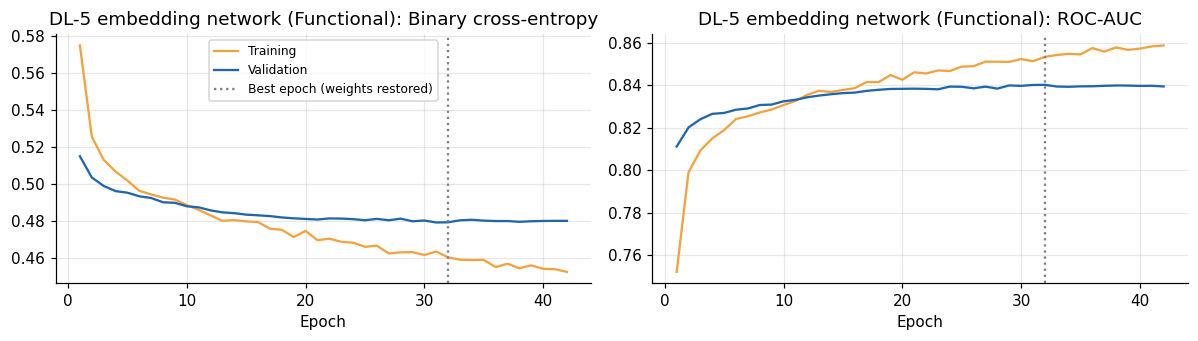

,accuracy,precision,recall,f1,roc_auc,pr_auc,train_roc_auc,best_epoch,epochs_run,parameters,fit_seconds
DL-4 search trial 10,0.7688,0.7780,0.6464,0.7061,0.8411,0.8261,0.8546,24,32,64769,25.5
DL-4 search trial 05,0.7665,0.7614,0.6651,0.7100,0.8408,0.8266,0.8530,11,19,58113,14.4
"DL-2 large MLP, no regularisation",0.7691,0.7838,0.6388,0.7039,0.8408,0.8261,0.8513,3,13,64769,10.2
DL-4 search trial 09,0.7686,0.7706,0.6569,0.7092,0.8407,0.8262,0.8537,44,52,56577,33.4
DL-4 search trial 01,0.7703,0.7899,0.6341,0.7035,0.8406,0.8262,0.8433,11,19,8385,12.3
DL-4 search trial 08,0.7716,0.7729,0.6633,0.7139,0.8406,0.8259,0.8494,19,27,23041,23.4
DL-5 embedding network (Functional),0.7706,0.7803,0.6487,0.7084,0.8402,0.8262,0.8533,32,42,60691,43.8
"DL-3 large MLP, regularised",0.7698,0.7763,0.6522,0.7089,0.8400,0.8255,0.8488,10,20,66561,19.8
DL-4 search trial 04,0.7708,0.7804,0.6493,0.7089,0.8398,0.8249,0.8542,12,20,20097,6.9
DL-4 search trial 07,0.7643,0.8005,0.6013,0.6867,0.8384,0.8237,0.8397,4,12,22145,5.2


Best deep learning model on validation ROC-AUC: DL-4 search trial 10


In [ ]:
keras.utils.set_random_seed(SEED)
embedding_model = build_embedding_model(
    CARDINALITIES,
    n_numeric=dl_inputs["embedding"]["train"]["numeric"].shape[1],
    hidden=best_config["hidden"],
    dropout=best_config["dropout"],
    l2=best_config["l2"],
    batch_norm=best_config["batch_norm"],
    optimizer=best_config["optimizer"],
    learning_rate=best_config["learning_rate"],
)
embedding_model.summary()
run_dl_experiment("DL-5 embedding network (Functional)", embedding_model, kind="embedding",
                  batch_size=best_config["batch_size"], config=best_config)
plot_histories(["DL-5 embedding network (Functional)"], "dl_learning_curve_embedding")

dl_table = results_table(dl_val_results)
best_dl_name = dl_table["roc_auc"].idxmax()
display(dl_table)
print(f"Best deep learning model on validation ROC-AUC: {best_dl_name}")

**Interpretation.** The Functional embedding model reaches a validation ROC-AUC of 0.840, against 0.841 for the best one-hot MLP. It is not a meaningful improvement. This is the expected result: the eight categorical features have between 2 and 13 levels, so one-hot encoding is already compact, and an embedding has little structure to discover. The embedding model's learning curves are smooth, with a best epoch of 32, and look very similar to trial 10's. The Functional API remains the natural design if higher-cardinality features (for example individual VLE resources) were added. The best deep learning model overall is **DL-4 search trial 10**, which is carried into the final evaluation.

## 9. Final evaluation on the held-out test set

Model selection is finished. The best model from each paradigm was chosen on validation ROC-AUC, and the test set is now used for the first and only time.

### 9.1 Choosing a decision threshold

A probability becomes a decision through a threshold. The default of 0.5 is arbitrary. Here the threshold is set on the validation set to maximise F1 for the at-risk class, then applied unchanged to the test set. In practice the right threshold depends on tutor capacity and on the relative cost of missing a struggling student compared with contacting one who was fine.

In [ ]:
def best_f1_threshold(y_true, proba):
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    return float(thresholds[np.argmax(f1[:-1])])


val_proba = {best_ml_name: positive_proba(best_ml_model, X_val), best_dl_name: predict_dl(best_dl_name, "val")}
thresholds = {name: best_f1_threshold(y_val, proba) for name, proba in val_proba.items()}

# Test-set probabilities for every traditional model and every named deep learning experiment.
reported_dl = [name for name in dl_runs if not name.startswith("DL-4")]
if best_dl_name not in reported_dl:
    reported_dl.append(best_dl_name)
test_proba = {name: positive_proba(model, X_test) for name, model in ml_models.items()}
test_proba.update({name: predict_dl(name, "test") for name in reported_dl})

test_results = {name: evaluate(y_test, proba) for name, proba in test_proba.items()}
test_table = results_table(test_results)
test_table.insert(0, "paradigm", ["Deep learning" if name in dl_runs else "Traditional ML" for name in test_table.index])
display(test_table)

finalists = pd.DataFrame({
    name: {"threshold": thresholds[name], **evaluate(y_test, test_proba[name], thresholds[name])}
    for name in (best_ml_name, best_dl_name)
}).T.round(4)
print("Finalists at their validation-tuned thresholds:")
display(finalists)

,paradigm,accuracy,precision,recall,f1,roc_auc,pr_auc
DL-4 search trial 10,Deep learning,0.7681,0.7703,0.6366,0.6971,0.8346,0.8132
DL-5 embedding network (Functional),Deep learning,0.7666,0.7682,0.6348,0.6952,0.8345,0.8138
"DL-3 large MLP, regularised",Deep learning,0.7673,0.7641,0.6438,0.6988,0.8345,0.8141
"DL-2 large MLP, no regularisation",Deep learning,0.7620,0.7632,0.6270,0.6884,0.8330,0.8114
Logistic Regression,Traditional ML,0.7650,0.7711,0.6252,0.6905,0.8306,0.8081
Logistic Regression (tuned),Traditional ML,0.7643,0.7706,0.6234,0.6892,0.8304,0.8078
DL-1 small MLP,Deep learning,0.7633,0.7683,0.6234,0.6883,0.8299,0.8091
Hist Gradient Boosting,Traditional ML,0.7613,0.7665,0.6192,0.6850,0.8285,0.8101
Hist Gradient Boosting (tuned),Traditional ML,0.7580,0.7619,0.6150,0.6806,0.8276,0.8088
Random Forest (tuned),Traditional ML,0.7577,0.7731,0.5976,0.6741,0.8271,0.8061


Finalists at their validation-tuned thresholds:


,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
Logistic Regression,0.3811,0.7479,0.6891,0.7267,0.7074,0.8306,0.8081
DL-4 search trial 10,0.3454,0.7295,0.6439,0.7940,0.7111,0.8346,0.8132


**Interpretation.** On the held-out test set, the best deep learning model (DL-4 trial 10) has the highest ROC-AUC (0.835). The best traditional model, the default logistic regression, scores 0.831, a margin of 0.004. The four leading neural networks (0.833–0.835) sit just above the logistic regressions (0.830–0.831), the small MLP (0.830) and gradient boosting (0.828), with random forest (0.826–0.827) and the SVM (0.809–0.822) slightly behind. Differences of this size need the significance test in Section 9.4 before any claim is made.

Test scores are about 0.007 below validation for both finalists (0.837 → 0.831 for logistic regression, 0.841 → 0.835 for the MLP). A small, uniform drop like this is expected after choosing the maximum of many candidates on the validation set. It shows that model selection did not badly overfit the validation data.

Moving the threshold trades precision for recall. At the F1-optimal threshold chosen on validation (0.38 for logistic regression, 0.35 for the MLP), recall rises from about 0.63 to 0.73 and 0.79 respectively, while precision falls from about 0.77 to 0.69 and 0.64. For an early-warning system, where a missed student is usually costlier than an unnecessary check-in, the lower thresholds are the better operating points.

### 9.2 Confusion matrices

The top row shows counts and the bottom row shows each true class normalised to 1, so the bottom-right cell is recall for at-risk students and the top-left cell is specificity.

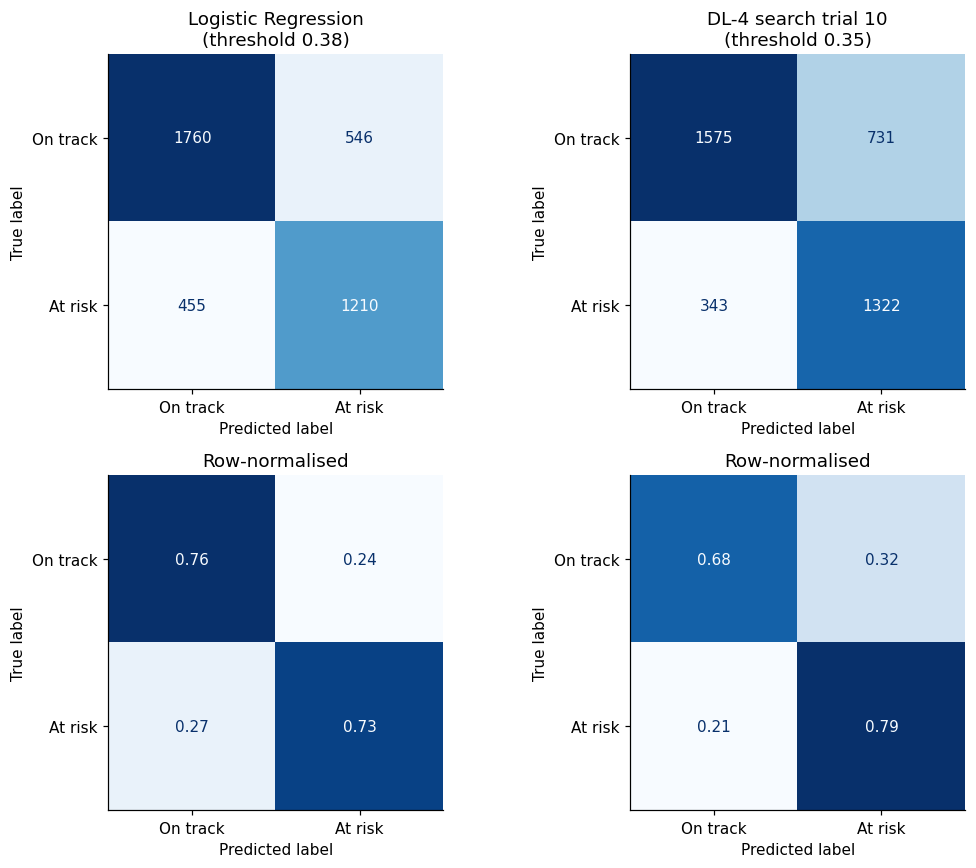


Logistic Regression
              precision    recall  f1-score   support

    On track      0.795     0.763     0.779      2306
     At risk      0.689     0.727     0.707      1665

    accuracy                          0.748      3971
   macro avg      0.742     0.745     0.743      3971
weighted avg      0.750     0.748     0.749      3971


DL-4 search trial 10
              precision    recall  f1-score   support

    On track      0.821     0.683     0.746      2306
     At risk      0.644     0.794     0.711      1665

    accuracy                          0.730      3971
   macro avg      0.733     0.738     0.728      3971
weighted avg      0.747     0.730     0.731      3971



In [ ]:
CLASS_NAMES = ["On track", "At risk"]
test_pred = {name: (test_proba[name] >= thresholds[name]).astype(int) for name in (best_ml_name, best_dl_name)}

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for column, name in enumerate((best_ml_name, best_dl_name)):
    for row, (normalize, fmt) in enumerate(((None, "d"), ("true", ".2f"))):
        ConfusionMatrixDisplay.from_predictions(
            y_test, test_pred[name], display_labels=CLASS_NAMES, normalize=normalize,
            values_format=fmt, cmap="Blues", colorbar=False, ax=axes[row, column],
        )
        axes[row, column].grid(False)
        axes[row, column].set_title(f"{name}\n(threshold {thresholds[name]:.2f})" if row == 0 else "Row-normalised")
save_figure("final_confusion_matrices")

for name in (best_ml_name, best_dl_name):
    print(f"\n{name}")
    print(classification_report(y_test, test_pred[name], target_names=CLASS_NAMES, digits=3))

**Interpretation.** The test set contains 1,665 at-risk students and 2,306 on-track students.

* **Logistic regression (threshold 0.38).** Flags 1,210 of the at-risk students (72.7%) and misses 455. It also flags 546 on-track students, so 31% of all flags are false alarms. Specificity is 76.3%.
* **MLP (threshold 0.35).** Flags about 1,322 at-risk students (79.4%) and misses about 343, at the cost of about 731 false alarms (specificity 68.3%).

For a university, a false negative is usually the more costly error. A missed student may fail or withdraw without any contact, while a false alarm costs a tutor's time and a possibly unnecessary email. Both thresholds favour recall over the 0.5 default. The MLP's lower threshold moves further in that direction, catching about 110 more at-risk students in exchange for about 185 more false alarms. The right operating point depends on how many students tutors can actually contact. That is an institutional decision that the threshold should be set to reflect, not something the model decides.

### 9.3 ROC and precision-recall curves

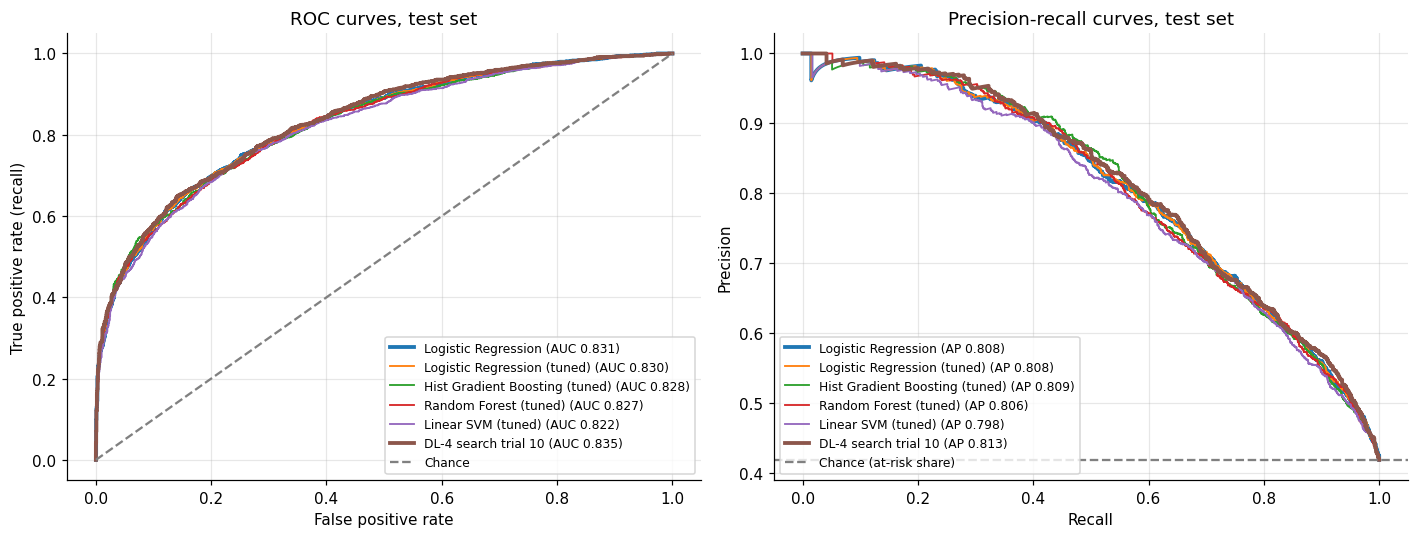

In [ ]:
curve_models = [best_ml_name] + [
    name for name in test_table.index if name.endswith("(tuned)") and name != best_ml_name
] + [best_dl_name]
palette = plt.cm.tab10(np.linspace(0, 1, 10))

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(13, 5))
for colour, name in zip(palette, curve_models):
    emphasis = 2.5 if name in (best_ml_name, best_dl_name) else 1.2
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    precision, recall, _ = precision_recall_curve(y_test, test_proba[name])
    ax_roc.plot(fpr, tpr, color=colour, linewidth=emphasis,
                label=f"{name} (AUC {test_results[name]['roc_auc']:.3f})")
    ax_pr.plot(recall, precision, color=colour, linewidth=emphasis,
               label=f"{name} (AP {test_results[name]['pr_auc']:.3f})")
ax_roc.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Chance")
ax_roc.set_xlabel("False positive rate")
ax_roc.set_ylabel("True positive rate (recall)")
ax_roc.set_title("ROC curves, test set")
ax_roc.legend(fontsize=8, loc="lower right")
ax_pr.axhline(y_test.mean(), color="grey", linestyle="--", label="Chance (at-risk share)")
ax_pr.set_xlabel("Recall")
ax_pr.set_ylabel("Precision")
ax_pr.set_title("Precision-recall curves, test set")
ax_pr.legend(fontsize=8, loc="lower left")
save_figure("final_roc_pr_curves")

**Interpretation.** The ROC and precision-recall curves of all five models almost coincide along their whole length. The paradigms produce near-identical rankings, consistent with the small AUC differences in Section 9.1. The PR curve gives a practical operating point. To reach 80% of at-risk students, a tutor would have to accept a precision of about 0.64, meaning roughly two in three contacted students would genuinely be at risk. At 60% recall, precision rises to about 0.78. Both are far above the 0.42 that random selection would give.

*Note:* in the run shown, the plot includes the tuned models plus the best MLP. The selected traditional finalist (the untuned logistic regression, test AUC 0.831) is now added explicitly; re-run this cell to refresh the figure. Its curve lies on top of the tuned logistic regression (0.830).

### 9.4 Is the difference between the two paradigms real?

A gap in ROC-AUC on one test set can be sampling noise. The bootstrap below resamples the test set with replacement, recomputes both AUCs each time, and reports a 95 percent interval for each model and for their difference. If the interval for the difference includes zero, the data do not support a claim that one paradigm is better.

Calibration is checked alongside: a model is well calibrated if, among students given a risk of 0.7, about 70 percent turn out to be at risk. This matters when the scores are shown to tutors as probabilities.

,2.5%,median,97.5%
Logistic Regression,0.8179,0.8307,0.8432
DL-4 search trial 10,0.8217,0.8345,0.8465
Difference (traditional - deep),-0.0083,-0.0039,0.0002


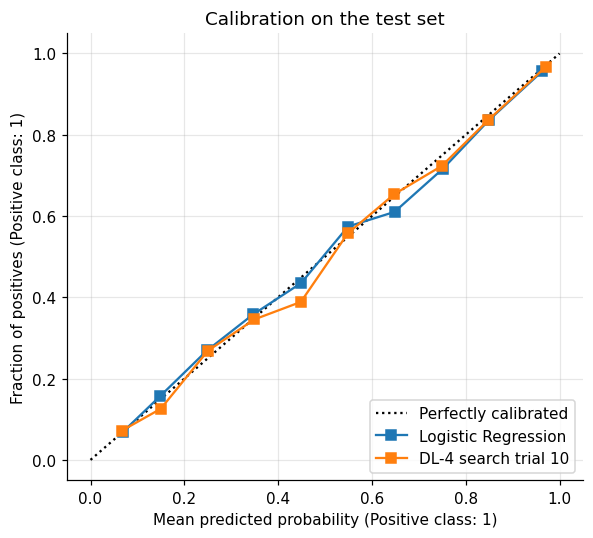

In [ ]:
def bootstrap_auc_difference(y_true, proba_a, proba_b, n_boot=N_BOOTSTRAP, seed=SEED):
    rng = np.random.default_rng(seed)
    rows = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if y_true[idx].min() == y_true[idx].max():
            continue
        auc_a = roc_auc_score(y_true[idx], proba_a[idx])
        auc_b = roc_auc_score(y_true[idx], proba_b[idx])
        rows.append((auc_a, auc_b, auc_a - auc_b))
    return np.percentile(np.array(rows), [2.5, 50, 97.5], axis=0)


low, median, high = bootstrap_auc_difference(y_test, test_proba[best_ml_name], test_proba[best_dl_name])
display(pd.DataFrame(
    {"2.5%": low, "median": median, "97.5%": high},
    index=[best_ml_name, best_dl_name, "Difference (traditional - deep)"],
).round(4))

fig, ax = plt.subplots(figsize=(5.5, 5))
for name in (best_ml_name, best_dl_name):
    CalibrationDisplay.from_predictions(y_test, test_proba[name], n_bins=10, name=name, ax=ax)
ax.set_title("Calibration on the test set")
save_figure("final_calibration")

**Interpretation.** The 95% bootstrap interval for the difference in ROC-AUC (traditional minus deep) is [−0.0083, +0.0002], with a median of −0.0039. The interval just includes zero, so the data do not support a claim that either paradigm is better on this test set. Any true advantage for the neural network is at most about 0.008 AUC, which is negligible in practice. The bootstrap resamples enrolments rather than students, so it slightly understates the uncertainty, which only strengthens this conclusion.

With performance tied, the choice should rest on other grounds. Logistic regression trains in about a second rather than about 25 seconds, needs no GPU or separate preprocessing artefact, and has coefficients that can be explained to tutors and students.

Both models are well calibrated. Their reliability curves follow the diagonal closely, with the largest deviations of about 0.06 (logistic regression in the 0.6–0.7 bin, the MLP in the 0.4–0.5 bin). A predicted risk of 0.7 therefore corresponds to roughly 70% of such students actually being at risk. This matters if the scores are shown to tutors as probabilities.

## 10. Error analysis

Aggregate metrics hide *who* the model fails. This section looks at the errors of the best traditional model from four angles: the original four-class outcome, the module, student subgroups, and the features that drive the predictions.

### 10.1 Errors by original outcome

The binary target merged four outcomes into two. Breaking the predictions back out shows which of the four the model finds hard.

,n,flagged_by_traditional,flagged_by_deep,mean_risk_score
final_result,,,,
Distinction,468,0.056,0.094,0.160
Pass,1838,0.283,0.374,0.300
Fail,1079,0.741,0.801,0.632
Withdrawn,586,0.700,0.782,0.601


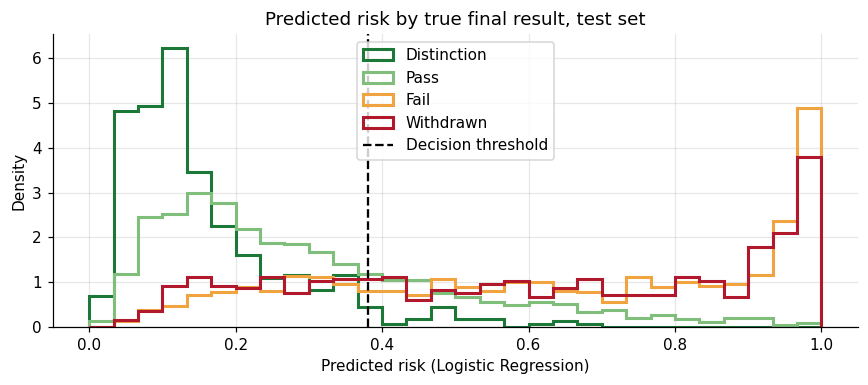

Both models agree on 90.8% of test enrolments.


In [ ]:
analysis = test_df[["final_result", "code_module", "code_presentation", "gender", "disability", "imd_band",
                    "age_band", "vle_total_clicks", "vle_active_days", "vle_days_since_last",
                    "asm_mean_score", "asm_submission_rate"]].copy()
analysis["y"] = y_test
analysis["proba"] = test_proba[best_ml_name]
analysis["pred"] = test_pred[best_ml_name]
analysis["proba_dl"] = test_proba[best_dl_name]
analysis["pred_dl"] = test_pred[best_dl_name]
analysis["error_type"] = np.select(
    [(analysis["y"] == 1) & (analysis["pred"] == 1), (analysis["y"] == 1) & (analysis["pred"] == 0),
     (analysis["y"] == 0) & (analysis["pred"] == 1)],
    ["True positive", "False negative (missed)", "False positive (false alarm)"],
    default="True negative",
)

by_outcome = analysis.groupby("final_result").agg(
    n=("y", "size"),
    flagged_by_traditional=("pred", "mean"),
    flagged_by_deep=("pred_dl", "mean"),
    mean_risk_score=("proba", "mean"),
).reindex(OUTCOME_ORDER).round(3)
display(by_outcome)

fig, ax = plt.subplots(figsize=(8, 3.6))
for outcome in OUTCOME_ORDER:
    ax.hist(analysis.loc[analysis["final_result"] == outcome, "proba"], bins=30, range=(0, 1),
            histtype="step", linewidth=2, density=True, color=OUTCOME_COLORS[outcome], label=outcome)
ax.axvline(thresholds[best_ml_name], color="black", linestyle="--", label="Decision threshold")
ax.set_xlabel(f"Predicted risk ({best_ml_name})")
ax.set_ylabel("Density")
ax.set_title("Predicted risk by true final result, test set")
ax.legend()
save_figure("error_risk_by_outcome")

print(f"Both models agree on {np.mean(analysis['pred'] == analysis['pred_dl']):.1%} of test enrolments.")

**Interpretation.** For the at-risk outcomes, the flagged rates are recall. Logistic regression catches 74.1% of students who go on to fail but only 70.0% of those who withdraw (the MLP: 80.1% and 78.2%). Withdrawals are slightly harder to anticipate, which fits the fact that some withdrawals have non-academic causes that do not show in study behaviour. For the successful outcomes, the flagged rates are false-alarm rates. Distinction students are almost never flagged (5.6%), but 28.3% of Pass students are flagged (37.4% by the MLP).

The histogram shows why. Distinction students are concentrated below a predicted risk of 0.2. Fail and Withdrawn students have a large peak near 1.0 but a long, flat tail across the whole range, and Pass students spread up to about 0.6. The overlap between Pass and the lower half of Fail/Withdrawn is where almost all errors occur: borderline but engaged students look alike at day 60.

The two paradigms agree on 90.8% of test enrolments. They have learned essentially the same decision rule and largely make the same mistakes.

### 10.2 What do the missed students look like?

In [ ]:
profile_columns = ["vle_total_clicks", "vle_active_days", "vle_days_since_last", "asm_mean_score",
                   "asm_submission_rate", "proba"]
error_order = ["True positive", "False negative (missed)", "False positive (false alarm)", "True negative"]
profile = analysis.groupby("error_type")[profile_columns].median().reindex(error_order)
profile.insert(0, "n", analysis["error_type"].value_counts().reindex(error_order))
display(profile.round(2))

missed = analysis[analysis["error_type"] == "False negative (missed)"]
print("Missed at-risk students by final result:")
display(missed["final_result"].value_counts().to_frame("count"))

,n,vle_total_clicks,vle_active_days,vle_days_since_last,asm_mean_score,asm_submission_rate,proba
error_type,,,,,,,
True positive,1210,190.0,13.0,8.0,64.25,1.0,0.81
False negative (missed),455,473.0,27.0,1.0,81.67,1.0,0.25
False positive (false alarm),546,261.5,18.0,4.0,70.00,1.0,0.53
True negative,1760,577.5,32.0,1.0,85.00,1.0,0.17


Missed at-risk students by final result:


,count
final_result,
Fail,279
Withdrawn,176


**Interpretation.** The missed students look like successful students, not struggling ones. Their median profile is 473 clicks, 27 active days, last login 1 day before the cutoff, a mean score of 81.7 and a 100% submission rate. This is close to the true negatives (577 clicks, 32 days, 1 day, 85.0) and far from the true positives (190 clicks, 13 days, 8 days, 64.3). Their median predicted risk is only 0.25.

Of the 455 missed students, 279 went on to fail and 176 to withdraw. For most of them, nothing in their first 60 days signalled trouble. Their difficulties appeared later in the module, or arose from circumstances outside the VLE. No model trained on these features could have caught them. This is a limit of the data available at the prediction day, not of the algorithm, and it explains why every model in the study converges at a similar ROC-AUC.

### 10.3 Performance by module and by student subgroup

A model can have a good overall score and still serve some groups poorly. Recall here is the share of truly at-risk students in the group who were flagged, and the false-positive rate is the share of on-track students wrongly flagged. Groups with fewer than 50 test enrolments are omitted because their rates are too noisy to interpret.

In [ ]:
def slice_report(frame, by, min_n=50):
    """Per-group size, base rate, flag rate, recall, false-positive rate and ROC-AUC."""
    rows = {}
    for value, group in frame.assign(**{by: frame[by].fillna("Missing")}).groupby(by):
        if len(group) < min_n:
            continue
        positives, negatives = group[group["y"] == 1], group[group["y"] == 0]
        rows[value] = {
            "n": len(group),
            "at_risk_rate": group["y"].mean(),
            "flagged_rate": group["pred"].mean(),
            "recall": positives["pred"].mean() if len(positives) else np.nan,
            "false_positive_rate": negatives["pred"].mean() if len(negatives) else np.nan,
            "roc_auc": roc_auc_score(group["y"], group["proba"]) if group["y"].nunique() == 2 else np.nan,
        }
    return pd.DataFrame.from_dict(rows, orient="index").rename_axis(by).round(3)


for column in ("code_module", "gender", "disability", "age_band", "imd_band"):
    display(slice_report(analysis, column))

,n,at_risk_rate,flagged_rate,recall,false_positive_rate,roc_auc
code_module,,,,,,
AAA,112,0.268,0.259,0.633,0.122,0.851
BBB,932,0.407,0.413,0.681,0.230,0.823
CCC,507,0.491,0.568,0.815,0.329,0.831
DDD,736,0.485,0.541,0.810,0.288,0.854
EEE,386,0.337,0.313,0.654,0.141,0.837
FFF,958,0.426,0.438,0.723,0.227,0.833
GGG,340,0.329,0.338,0.545,0.237,0.737


,n,at_risk_rate,flagged_rate,recall,false_positive_rate,roc_auc
gender,,,,,,
F,1788,0.410,0.423,0.673,0.250,0.801
M,2183,0.427,0.458,0.769,0.225,0.853


,n,at_risk_rate,flagged_rate,recall,false_positive_rate,roc_auc
disability,,,,,,
N,3623,0.410,0.428,0.717,0.226,0.83
Y,348,0.514,0.595,0.810,0.367,0.83


,n,at_risk_rate,flagged_rate,recall,false_positive_rate,roc_auc
age_band,,,,,,
0-35,2771,0.432,0.466,0.735,0.262,0.823
35-55,1177,0.394,0.389,0.703,0.185,0.844


,n,at_risk_rate,flagged_rate,recall,false_positive_rate,roc_auc
imd_band,,,,,,
0-10,400,0.528,0.618,0.806,0.407,0.829
10-20,413,0.513,0.569,0.797,0.328,0.804
20-30,433,0.460,0.527,0.779,0.312,0.826
30-40,453,0.437,0.439,0.707,0.231,0.817
40-50,381,0.415,0.459,0.753,0.251,0.848
50-60,364,0.409,0.423,0.752,0.195,0.858
60-70,350,0.386,0.351,0.593,0.200,0.797
70-80,346,0.387,0.393,0.694,0.203,0.833
80-90,331,0.332,0.314,0.618,0.163,0.803


**Interpretation.** Performance is broadly consistent across six of the seven modules (ROC-AUC 0.82–0.85). GGG is a clear outlier at 0.737, with the lowest recall (0.545). GGG has the profile noted in Section 3.3: few withdrawals and a high fail share. Its failing students appear to stay engaged and submit work through day 60, so the behavioural features, which work well for disengagement, have little to detect. Module-specific assessment structure (how much weight is due before day 60) is a plausible further reason and is worth checking.

The demographic slices show the fairness issue raised earlier. The false-positive rate rises steadily with deprivation, from 0.161 in the least deprived band (90–100) to 0.407 in the most deprived (0–10), a ratio of 2.5. Students with a declared disability are wrongly flagged at 0.367 against 0.226 for others, even though ROC-AUC is identical (0.83) for both groups. The model is equally good at ranking within each group but applies a higher baseline risk to disadvantaged groups. Their at-risk rates really are higher (0.528 against 0.316 by deprivation), so this is partly an accurate reflection of the data.

Women have lower recall (0.673 against 0.769) and lower ROC-AUC (0.801 against 0.853) than men. Students with a missing deprivation band have the lowest recall of any group (0.536).

If the flag triggers supportive contact, the higher false-positive rate for deprived and disabled students is a modest cost. Some on-track students receive an offer of help they did not need. If the flag fed into anything restrictive or stigmatising, the same disparity would be unacceptable. A deployed system should monitor these rates by group and could set group-aware thresholds or remove demographic features if equal error rates were required.

### 10.4 Which features does the model rely on?

Permutation importance shuffles one raw feature at a time in the validation set and measures the drop in ROC-AUC. It is computed on the whole pipeline, so each categorical feature is treated as one feature rather than as many one-hot columns. Correlated features share importance between them, so a low value does not prove a feature is useless.

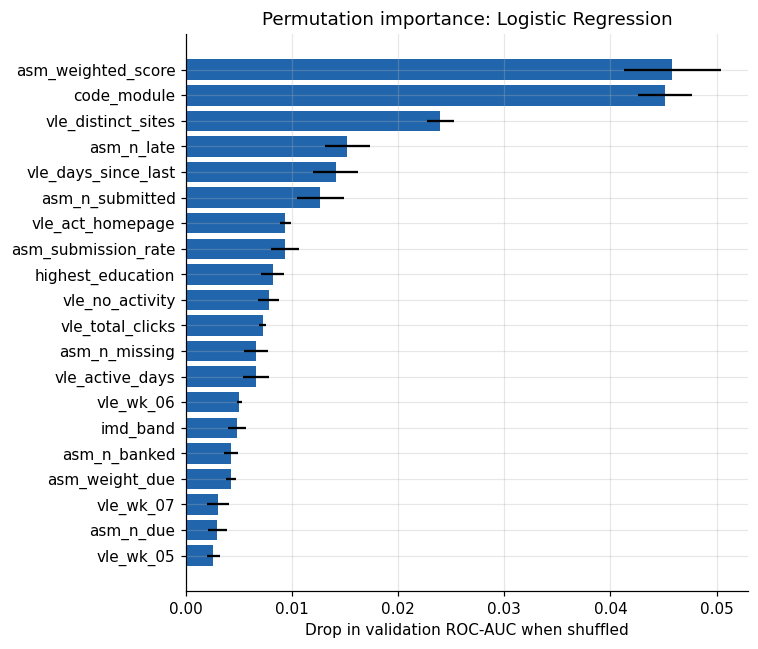

In [ ]:
importance = permutation_importance(
    best_ml_model, X_val, y_val, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1
)
importance_table = pd.DataFrame(
    {"mean_auc_drop": importance.importances_mean, "std": importance.importances_std}, index=FEATURE_COLS
).sort_values("mean_auc_drop", ascending=False)

top = importance_table.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top["mean_auc_drop"], xerr=top["std"], color="#2166ac")
ax.set_xlabel("Drop in validation ROC-AUC when shuffled")
ax.set_title(f"Permutation importance: {best_ml_name}")
save_figure("error_permutation_importance")

**Interpretation.** The most important features are a mix of performance, context and engagement. They are `asm_weighted_score` (an AUC drop of 0.046 when shuffled), `code_module` (0.045), `vle_distinct_sites` (0.024), `asm_n_late` (0.015), `vle_days_since_last` (0.014) and `asm_n_submitted` (0.013). Assessment features dominate, consistent with the ablation in Section 7.5, where assessment features alone reached 0.810. `code_module` ranks second because the base rate of failure differs so much between modules (Section 3.3). Breadth of engagement (distinct resources) and recency matter more than raw click volume.

Demographic features rank low. `highest_education` (0.008) and `imd_band` (0.005) are the only ones in the top 20, while gender, disability and age band do not appear. The model's decisions therefore rest mainly on behaviour, which is reassuring. However, Section 10.3 shows that even a small weight on deprivation, combined with its correlation with behaviour, produces unequal false-positive rates. Low importance does not by itself guarantee equal treatment.

### 10.5 Robustness check: predicting a future presentation

The main split is random across presentations. A deployed model would be trained on past presentations and applied to the next one. This check retrains the best traditional configuration on every presentation except the last (2014J) and tests on 2014J.

In [ ]:
future = features["code_presentation"] == "2014J"
temporal_model = clone(best_ml_model).fit(features.loc[~future, FEATURE_COLS], features.loc[~future, TARGET])
temporal_proba = positive_proba(temporal_model, features.loc[future, FEATURE_COLS])
temporal_metrics = evaluate(features.loc[future, TARGET].to_numpy(), temporal_proba)

display(pd.DataFrame({
    "Random split by student (test set)": {"n_test": len(y_test), **test_results[best_ml_name]},
    "Temporal holdout (2014J)": {"n_test": int(future.sum()), **temporal_metrics},
}).T.round(4))

,n_test,accuracy,precision,recall,f1,roc_auc,pr_auc
Random split by student (test set),3971.0,0.7650,0.7711,0.6252,0.6905,0.8306,0.8081
Temporal holdout (2014J),8816.0,0.7642,0.7651,0.5499,0.6399,0.8149,0.7700


**Interpretation.** Training on 2013B, 2013J and 2014B and testing on the following presentation (2014J, 8,816 enrolments) gives a ROC-AUC of 0.815 and a PR-AUC of 0.770, compared with 0.831 and 0.808 on the random student-disjoint split. Recall at the 0.5 threshold falls from 0.625 to 0.550.

The drop of 0.016 AUC is modest but real. Part of it comes from drift between presentations in course design, cohorts and VLE use. Part comes from a smaller training set, since 2014J is a third of the cohort. The model transfers to a new cohort with a small loss, so the random-split score slightly overstates real-world performance. A deployed system should be retrained each presentation and its threshold re-checked, because recall is the metric that drifted most. Some 2014J students also appear in earlier presentations, so this check is not fully student-disjoint.

## 11. Saving artefacts

The best model from each paradigm is saved for the Google Drive folder:

* `best_traditional_model.joblib` is the full scikit-learn pipeline, preprocessing included, so it accepts a raw feature table.
* `best_deep_model.keras` is the Keras model in the native format, with an `.h5` copy for compatibility.
* `deep_model_preprocessing.joblib` holds the fitted transformers the Keras model needs, because preprocessing is not part of the network.
* `run_metadata.json` records the configuration, thresholds, test metrics and library versions.

Each saved model is reloaded and its predictions compared with the originals, to prove the files work.

In [ ]:
ml_path = MODEL_DIR / "best_traditional_model.joblib"
dl_path = MODEL_DIR / "best_deep_model.keras"
prep_path = MODEL_DIR / "deep_model_preprocessing.joblib"

joblib.dump(best_ml_model, ml_path)
best_dl_run = dl_runs[best_dl_name]
best_dl_run["model"].save(str(dl_path))
try:
    best_dl_run["model"].save(str(MODEL_DIR / "best_deep_model.h5"))
except Exception as error:   # the legacy format is optional
    print(f"Skipped the .h5 copy: {error}")
joblib.dump(
    {
        "input_kind": best_dl_run["kind"],
        "dense_preprocessor": dl_preprocessor,
        "numeric_preprocessor": numeric_prep,
        "category_encoder": category_encoder,
        "categorical_columns": CATEGORICAL_COLS,
        "feature_columns": FEATURE_COLS,
    },
    prep_path,
)

metadata = {
    "cutoff_day": CUTOFF_DAY,
    "seed": SEED,
    "fast_mode": FAST_MODE,
    "cohort_size": int(len(features)),
    "split_sizes": {name: int(len(y)) for name, y in y_splits.items()},
    "best_traditional_model": best_ml_name,
    "best_deep_model": best_dl_name,
    "best_deep_config": {key: (list(value) if isinstance(value, tuple) else value)
                         for key, value in best_dl_run["config"].items()},
    "thresholds": thresholds,
    "test_metrics": {name: {metric: float(value) for metric, value in test_results[name].items()}
                     for name in (best_ml_name, best_dl_name)},
    "library_versions": LIBRARY_VERSIONS,
}
(MODEL_DIR / "run_metadata.json").write_text(json.dumps(metadata, indent=2))

# Reload both models and confirm they reproduce the test predictions.
reloaded_ml = joblib.load(ml_path)
assert np.allclose(positive_proba(reloaded_ml, X_test), test_proba[best_ml_name])
reloaded_dl = keras.models.load_model(str(dl_path))
reloaded_proba = reloaded_dl.predict(
    make_dataset(dl_inputs[best_dl_run["kind"]]["test"], y_test, best_dl_run["batch_size"]), verbose=0
).ravel()
assert np.allclose(reloaded_proba, test_proba[best_dl_name], atol=1e-5)

print("Saved and verified:")
for path in sorted(MODEL_DIR.iterdir()):
    print(f"  {path.name:<36} {path.stat().st_size / 1e6:6.2f} MB")

Saved and verified:
  best_deep_model.h5                     0.56 MB
  best_deep_model.keras                  0.56 MB
  best_traditional_model.joblib          0.01 MB
  deep_model_preprocessing.joblib        0.02 MB
  run_metadata.json                      0.00 MB


In Colab, the models and figures are already in `My Drive/oulad_summative`. The cell below adds the raw dataset zip and lists the folder's contents. Then set the folder's sharing to "Anyone with the link can view".

In [ ]:
if IN_COLAB:
    shutil.copy2(DATA_DIR / "oulad_raw.zip", OUTPUT_DIR / "oulad_raw.zip")
    print(f"Contents of {OUTPUT_DIR}:")
    for path in sorted(OUTPUT_DIR.rglob("*")):
        if path.is_file():
            print(f"  {str(path.relative_to(OUTPUT_DIR)):<45} {path.stat().st_size / 1e6:8.2f} MB")

Contents of /content/drive/MyDrive/oulad_summative:
  figures/dl_learning_curve_best_search.png         0.11 MB
  figures/dl_learning_curve_embedding.png           0.12 MB
  figures/dl_learning_curves_capacity.png           0.34 MB
  figures/eda_feature_correlations.png              0.14 MB
  figures/eda_feature_distributions.png             0.10 MB
  figures/eda_outcome_by_group.png                  0.16 MB
  figures/eda_outcome_distribution.png              0.06 MB
  figures/eda_weekly_clicks_by_outcome.png          0.19 MB
  figures/eda_withdrawal_timing.png                 0.07 MB
  figures/error_permutation_importance.png          0.13 MB
  figures/error_risk_by_outcome.png                 0.06 MB
  figures/final_calibration.png                     0.10 MB
  figures/final_confusion_matrices.png              0.10 MB
  figures/final_roc_pr_curves.png                   0.25 MB
  figures/ml_cutoff_sensitivity.png                 0.09 MB
  figures/ml_feature_ablation.png               

## 12. Conclusions and limitations

**Headline result.** The best traditional model was a default logistic regression (test ROC-AUC 0.831, PR-AUC 0.808). The best deep learning model was a three-layer MLP found by random search (DL-4 trial 10: test ROC-AUC 0.835, PR-AUC 0.813). The 95% bootstrap interval for their difference, [−0.008, +0.000], includes zero, so the two paradigms are statistically indistinguishable on this test set. Every serious model, from logistic regression to a Functional-API embedding network, landed between 0.822 and 0.835. Given equal accuracy, logistic regression is the more practical choice: it trains in about a second, is well calibrated and can be explained.

**What mattered most.** The features mattered far more than the algorithm. Background features alone gave a ROC-AUC of 0.649, assessment features alone 0.810, VLE features alone 0.765, and all features together 0.836. The behavioural families are complementary. The most important individual features were the weighted assessment score, the module, the number of distinct VLE resources used, late submissions and days since the last login. Demographic features ranked low.

**Earliness.** ROC-AUC rises from 0.721 on day 0 to 0.836 on day 60 and 0.894 on day 120. Day 60 recovers about two-thirds of that gain while leaving roughly three-quarters of the module for intervention. Running the model at several checkpoints would combine early reach with later accuracy.

**Where it fails.** Most errors fall on the boundary between Pass and Fail. Missed students looked engaged and successful at day 60 (median score 82, active 27 days), so their outcome was not visible in the data. Withdrawals were caught slightly less often than failures. Module GGG was markedly harder (AUC 0.737). False-positive rates were 2.5 times higher in the most deprived band than the least deprived, and higher for students with a declared disability. Performance on a later presentation (2014J) was 0.016 AUC lower than on the random split.

**Limitations of the dataset and the method.**

* *One institution, one period.* OULAD covers seven modules at a single UK distance-learning university in 2013 and 2014. Behaviour on its VLE may not transfer to campus universities, to other countries, or to current online teaching.
* *The cohort is conditional.* Students who left before day 60 are excluded, so the model says nothing about the 61.9% of withdrawals that happen before then.
* *The label merges different situations.* Withdrawal for personal or financial reasons and academic failure are treated as the same class, although they call for different support and only one of them is likely to show in study behaviour.
* *Clicks are a proxy.* The VLE records clicks, not learning. Students who study offline, or download materials once, look disengaged.
* *Assumed data availability.* Assessment scores are treated as known on the day of submission, which ignores marking delay.
* *Coarse and partly missing demographics.* Deprivation band is missing for 3.4% of students and is UK-specific; age is given in three bands only.
* *Limited search.* Hyperparameter searches used a small number of candidates and a single random seed, so differences below about 0.002 AUC between models are within run-to-run noise.
* *Historical bias.* The model learns from past outcomes, which reflect past inequalities in support. Section 10.3 measures how its errors are distributed, but measuring a disparity does not remove it.

**Future work.** Sequence models (for example an LSTM or 1D-CNN over the daily click series) could use the order of events that the weekly aggregates discard. A four-class or time-to-event formulation would separate withdrawal from failure. Fairness-aware thresholds could be evaluated against the subgroup error rates reported here. Evaluating a real intervention would require a controlled trial, since predicting risk is not the same as reducing it.